In [493]:
## 1. Paquetes y datos

In [494]:
import warnings
warnings.filterwarnings("ignore")
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, cohen_kappa_score
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

from google.colab import drive
drive.mount('/content/drive')

# Orange: carpeta de los datos. CAMBIEN ESTA RUTA a donde tengan los archivos del curso
RUTA = '/content/drive/MyDrive/Proyecto BRIO/'
resenas = pd.read_csv(RUTA + 'appodio_resenas.csv')
muestra = pd.read_csv(RUTA + 'appodio_muestra_para_etiquetar.csv')
panel   = pd.read_csv(RUTA + 'appodio_panel_app_mes.csv')
print(resenas.shape, muestra.shape, panel.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(383078, 20) (1200, 12) (556, 31)


In [495]:
## 2. Verificación de la fuente de datos

In [496]:
neg = resenas[resenas['score'] <= 3]
print('Negativas 1-3:', len(neg), f'({len(neg)/len(resenas):.0%})')
print('Duplicados app+texto:', neg.duplicated(subset=['app','texto_n']).sum())
neg_sd = neg.drop_duplicates(subset=['app','texto_n'])
print('Sin duplicados:', len(neg_sd))
print('Sin versión:', f"{neg['version'].isna().mean():.1%}")
print('1-2 palabras:', (neg['n_palabras'] <= 2).sum(), '| sin dup:', (neg_sd['n_palabras'] <= 2).sum())
print(neg['tipo_app'].value_counts())
print('Fechas:', resenas['fecha'].min(), 'a', resenas['fecha'].max())

Negativas 1-3: 177176 (46%)
Duplicados app+texto: 13129
Sin duplicados: 164047
Sin versión: 15.7%
1-2 palabras: 13255 | sin dup: 4007
tipo_app
billetera            94746
banco tradicional    79901
banco digital         2529
Name: count, dtype: int64
Fechas: 2023-01-01 00:02:14 a 2026-07-31 23:57:52


In [497]:
## 3. Ficha: piloto de 50 reseñas al azar (semilla 42)

In [498]:
muestra = muestra.merge(resenas[['id','tipo_app']], on='id', how='left')
orden = muestra.sample(frac=1, random_state=42).reset_index(drop=True)
orden.to_csv(RUTA + 'muestra_ordenada.csv', index=False)
orden.head(50)[['id','app','tipo_app','score','fecha','text','grave','equipo','etiquetador','nota']] \
     .to_csv(RUTA + 'piloto_50.csv', index=False, encoding='utf-8-sig')
print(orden.head(50)['tipo_app'].value_counts())

tipo_app
banco tradicional    24
billetera            21
banco digital         5
Name: count, dtype: int64


In [499]:
### 3.1 Tasa base y costos del piloto (ficha)

In [500]:

ARCHIVO_ETIQ = 'PILOTO_etiquetado.csv'
p = pd.read_csv(RUTA + ARCHIVO_ETIQ)
temas = ['tema_fraude','tema_plata_no_llega','tema_acceso_bloqueo','tema_cobros']
p = p.merge(resenas[['id'] + temas], on='id')
print('Filas:', len(p), '| sin etiqueta:', p['grave'].isna().sum())


tasa = p['grave'].mean(); ee = np.sqrt(tasa*(1-tasa)/len(p))
print(f'Tasa base: {tasa:.0%}  IC95%: {max(0,tasa-1.96*ee):.0%} a {tasa+1.96*ee:.0%}')
print(p.groupby('tipo_app')['grave'].agg(['mean','count']))
print(p.groupby('score')['grave'].agg(['mean','count']))
print(p.loc[p['grave']==1, 'equipo'].value_counts())


p['regla'] = (p[temas].sum(axis=1) > 0).astype(int)


def costo(y, d):
    return (5*((y==1)&(d==0)).sum() + ((y==0)&(d==1)).sum()) / len(y) * 1000
print('Regla:', costo(p['grave'], p['regla']))
print('Escalar todo:', costo(p['grave'], np.ones(len(p))))
print('No escalar:', costo(p['grave'], np.zeros(len(p))))
print(pd.crosstab(p['grave'], p['regla'], rownames=['real'], colnames=['regla']))

Filas: 50 | sin etiqueta: 0
Tasa base: 22%  IC95%: 11% a 33%
                       mean  count
tipo_app                          
banco digital      0.000000      5
banco tradicional  0.208333     24
billetera          0.285714     21
           mean  count
score                 
1      0.354839     31
2      0.000000     10
3      0.000000      9
equipo
acceso_identidad        6
tecnologia_app          3
cobros_tarifas          1
pagos_transferencias    1
Name: count, dtype: int64
Regla: 440.0
Escalar todo: 780.0
No escalar: 1100.0
regla   0   1
real         
0      27  12
1       2   9


In [501]:
## 4. Reparto del etiquetado (400 reseñas + 50 extras de prueba)

In [502]:
# ============================================================
# CELDA 5 — Repartir el etiquetado (protocolo del brief)
# ============================================================

ARCHIVO_ORDEN = 'muestra_ordenada.csv'   # muestra barajada con SEMILLA = 42 (ficha)
FECHA_CORTE   = '2025-07-01'             # antes = entrenamiento, desde aquí = prueba
N_ETIQUETAR   = 400                      # mínimo del brief
N_DOBLE       = 100                      # reseñas que etiquetan los dos (kappa)
N_EXTRA       = 50                       # extras de prueba para llegar a 40 graves
COLUMNAS      = ['id','app','tipo_app','score','fecha','text',
                 'grave','equipo','etiquetador','nota']

# --- 1. Cargar la muestra en orden aleatorio ---
orden = pd.read_csv(RUTA + ARCHIVO_ORDEN)

# --- 2. Marcar qué reseñas son de prueba (partición temporal) ---
orden['prueba'] = pd.to_datetime(orden['fecha']) >= FECHA_CORTE

# --- 3. Extras de prueba (desde la reseña 401, solo de jul-2025 en adelante) ---
resto = orden.iloc[N_ETIQUETAR:]
extra = resto[resto['prueba']].head(N_EXTRA)

# --- 4. Repartir el trabajo ---
# Sergio: filas 51-100 (ya tiene 1-50 del piloto) + 101-275 + mitad de extras
sergio = pd.concat([orden.iloc[50:N_DOBLE],
                    orden.iloc[N_DOBLE:275],
                    extra.iloc[:N_EXTRA//2]])
# Amadeo: filas 1-100 (doble, sin ver las de Sergio) + 276-400 + otra mitad de extras
amadeo = pd.concat([orden.iloc[0:N_DOBLE],
                    orden.iloc[275:N_ETIQUETAR],
                    extra.iloc[N_EXTRA//2:]])

# --- 5. Guardar los archivos en Drive ---
sergio[COLUMNAS].to_csv(RUTA + 'etiquetar_SERGIO.csv', index=False, encoding='utf-8-sig')
amadeo[COLUMNAS].to_csv(RUTA + 'etiquetar_AMADEO.csv', index=False, encoding='utf-8-sig')

print('Sergio:', len(sergio), '| Amadeo:', len(amadeo))
print('De prueba -> Sergio:', sergio['prueba'].sum(), '| Amadeo:', amadeo['prueba'].sum())

Sergio: 250 | Amadeo: 250
De prueba -> Sergio: 107 | Amadeo: 109


In [503]:
## 5. Etiquetas del equipo

In [504]:
ARCHIVOS_ETIQUETAS = [
    "PILOTO_etiquetado.csv",    # reseñas 1-50 (Sergio)
    "SERGIO_etiquetado.csv",    # reseñas 51-275 + 25 extras (Sergio)
    "AMADEO_etiquetado.csv",    # reseñas 1-100 (doble) + 276-400 + 25 extras (Amadeo)
]

# Leer y unir los archivos
etiquetas = pd.concat([pd.read_csv(RUTA + a) for a in ARCHIVOS_ETIQUETAS], ignore_index=True)
etiquetas = etiquetas[["id", "grave", "equipo", "etiquetador", "nota"]]
# las 100 de la doble etiqueta aparecen dos veces: se deja la de Sergio (ya resuelta con la regla final)
etiquetas = etiquetas.drop_duplicates(subset="id", keep="first")

print(etiquetas.shape)
etiquetas.head()

(450, 5)


,id,grave,equipo,etiquetador,nota
0,1ce60a27-3ac7-4cc2-801c-14d667bb83ed,0,NaN,SG,NaN
1,76c72d39-df38-4a5e-841e-2f654944e081,0,NaN,SG,NaN
2,b7e1b2fd-f95e-4e31-9565-9b7fc3fc2146,0,NaN,SG,Se desinstalo mas no habla de perdida de plata
3,48d992ea-2c60-4d53-b225-043516fe7748,0,NaN,SG,No habla de perdida de plata
4,cf843b71-d6e6-4da8-a0bf-ddfb51c1230a,1,cobros_tarifas,SG,NaN


In [505]:
### 5.1 Acuerdo entre etiquetadores (doble etiqueta y kappa)

In [506]:
sergio = pd.concat([pd.read_csv(RUTA + "PILOTO_etiquetado.csv"), pd.read_csv(RUTA + "SERGIO_etiquetado.csv")])
amadeo = pd.read_csv(RUTA + "AMADEO_etiquetado.csv")
doble = sergio[["id", "grave"]].rename(columns={"grave": "grave_a"}).merge(
        amadeo[["id", "grave"]].rename(columns={"grave": "grave_b"}), on="id")
doble.to_csv(RUTA + "appodio_doble_etiqueta.csv", index=False)

print("Reseñas con doble etiqueta:", len(doble))
print("Acuerdo simple:", round((doble["grave_a"] == doble["grave_b"]).mean(), 3))
print("Kappa de Cohen:", round(cohen_kappa_score(doble["grave_a"], doble["grave_b"]), 3))
pd.crosstab(doble["grave_a"], doble["grave_b"], rownames=["Sergio"], colnames=["Amadeo"])

Reseñas con doble etiqueta: 100
Acuerdo simple: 0.99
Kappa de Cohen: 0.967


Amadeo,0,1
Sergio,,
0,81,0
1,1,18


In [507]:
pd.DataFrame({
    "repetidas": [etiquetas["id"].duplicated().sum()],
    "sin grave": [etiquetas["grave"].isna().sum()],
    "graves": [int(etiquetas["grave"].sum())],
    "% graves": [round(etiquetas["grave"].mean() * 100, 1)],
})

,repetidas,sin grave,graves,% graves
0,0,0,104,23.1


In [508]:
### 5.2 Unir etiquetas con los datos de cada reseña

In [509]:
# Traer de 'resenas' el texto, la app, las estrellas, la fecha y las demás variables
muestra = etiquetas.merge(resenas, on="id", how="left")

# Marcar entrenamiento y prueba (partición temporal del brief)
FECHA_CORTE = "2025-07-01"
muestra["prueba"] = pd.to_datetime(muestra["fecha"]) >= FECHA_CORTE

print(muestra.shape)
muestra[["id", "app", "tipo_app", "score", "fecha", "prueba", "grave", "equipo"]].head()

(450, 25)


,id,app,tipo_app,score,fecha,prueba,grave,equipo
0,1ce60a27-3ac7-4cc2-801c-14d667bb83ed,bogota,banco tradicional,1,2023-03-28 20:29:41,False,0,NaN
1,76c72d39-df38-4a5e-841e-2f654944e081,avvillas,banco tradicional,1,2023-02-16 14:04:45,False,0,NaN
2,b7e1b2fd-f95e-4e31-9565-9b7fc3fc2146,daviplata,billetera,1,2023-06-06 22:37:30,False,0,NaN
3,48d992ea-2c60-4d53-b225-043516fe7748,avvillas,banco tradicional,1,2024-08-01 17:37:24,False,0,NaN
4,cf843b71-d6e6-4da8-a0bf-ddfb51c1230a,bogota,banco tradicional,1,2023-06-28 20:25:48,False,1,cobros_tarifas


In [510]:
### 5.3 Tasa base y partición en entrenamiento y prueba

In [511]:
# Proporción de cada clase (Regresion_Logistica.ipynb, sección 5.1)
print("Tasa base (proporción de graves):")
print(muestra["grave"].value_counts(normalize=True).round(3))

# Reseñas y graves en cada parte (mismo formato que KMeans.ipynb: groupby + agg)
muestra.groupby("prueba")["grave"].agg(["count", "sum", "mean"]).round(3)

Tasa base (proporción de graves):
grave
0    0.769
1    0.231
Name: proportion, dtype: float64


,count,sum,mean
prueba,,,
False,250,59,0.236
True,200,45,0.225


In [512]:
### 5.4 Tasa de graves por tipo de app, estrellas y longitud

In [513]:
# Longitud en tres grupos (el brief pide la tasa de graves por longitud)
muestra["largo"] = pd.cut(muestra["n_palabras"], bins=[0, 10, 30, 1000],
                          labels=["corta (≤10)", "media (11-30)", "larga (>30)"])

# Tasa de graves por grupo (for como en la sección 4.4 + groupby/agg como en KMeans.ipynb)
for col in ["tipo_app", "score", "largo"]:
    print(f"\n% de graves según {col}:")
    print(muestra.groupby(col)["grave"].agg(["count", "mean"]).round(3))


% de graves según tipo_app:
                   count   mean
tipo_app                       
banco digital         19  0.105
banco tradicional    230  0.196
billetera            201  0.284

% de graves según score:
       count   mean
score              
1        349  0.252
2         59  0.153
3         42  0.167

% de graves según largo:
               count   mean
largo                      
corta (≤10)       99  0.061
media (11-30)    209  0.206
larga (>30)      142  0.387


In [514]:
## 6. Exploración de todas las reseñas negativas

In [515]:
neg = resenas[resenas["score"] <= 3].drop_duplicates(subset=["app", "texto_n"])
print(neg.shape)

(164047, 20)


In [516]:
pd.crosstab(neg["tipo_app"], neg["score"], rownames=["Tipo de app"], colnames=["Estrellas"], normalize="index").round(3)


Estrellas,1,2,3
Tipo de app,,,
banco digital,0.735,0.140,0.125
banco tradicional,0.821,0.105,0.074
billetera,0.756,0.124,0.120


In [517]:
resumen = neg.groupby("tipo_app")["n_palabras"].describe()[["mean", "50%", "std", "min", "max"]]
resumen.columns = ["media", "mediana", "DE", "mínimo", "máximo"]
resumen.round(2)

,media,mediana,DE,mínimo,máximo
tipo_app,,,,,
banco digital,29.32,23.0,21.87,0.0,103.0
banco tradicional,23.63,18.0,19.07,0.0,111.0
billetera,24.54,19.0,19.84,0.0,129.0


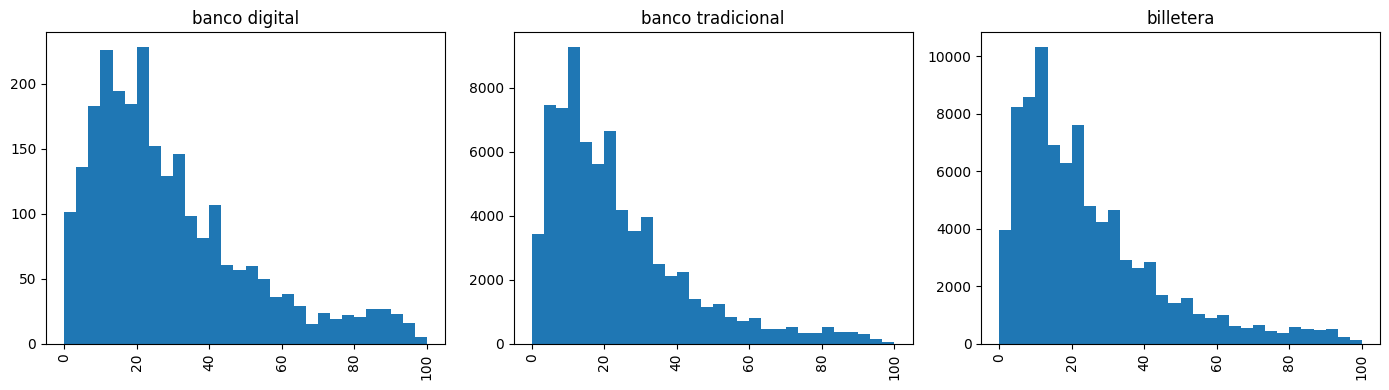

In [518]:
neg.hist(column="n_palabras", by="tipo_app", figsize=(14, 4), bins=30, range=(0, 100), layout=(1, 3))
plt.tight_layout()
plt.show()

In [519]:
### 6.1 Temas de palabras clave por app

In [520]:
TEMAS = ["tema_fraude", "tema_fallas_app", "tema_plata_no_llega",
         "tema_acceso_bloqueo", "tema_cobros", "tema_atencion"]

neg.groupby(["tipo_app", "app"])[TEMAS].mean().round(3)

tema_fraude  tema_fallas_app  \
tipo_app          app                                         
banco digital     lulo               0.048            0.303   
banco tradicional agrario            0.008            0.377   
                  avvillas           0.020            0.433   
                  bancolombia        0.019            0.429   
                  bbva               0.018            0.526   
                  bogota             0.035            0.401   
                  cajasocial         0.014            0.463   
                  colpatria          0.021            0.451   
                  davivienda         0.012            0.595   
                  falabella          0.018            0.454   
                  popular            0.014            0.455   
billetera         dale               0.049            0.360   
                  daviplata          0.047            0.437   
                  movii              0.064            0.259   
                  nequi              0.041            0.352   

                               tema_plata_no_llega  tema_acceso_bloqueo  \
tipo_app          app                                                     
banco digital     lulo                       0.145                0.392   
banco tradicional agrario                    0.149                0.409   
                  avvillas                   0.145                0.377   
                  bancolombia                0.261                0.330   
                  bbva                       0.227                0.287   
                  bogota                     0.221                0.202   
                  cajasocial                 0.185                0.282   
                  colpatria                  0.188                0.274   
                  davivienda                 0.100                0.299   
                  falabella                  0.121                0.223   
                  popular                    0.148                0.250   
billetera         dale                       0.248                0.359   
                  daviplata                  0.262                0.319   
                  movii                      0.269                0.487   
                  nequi                      0.205                0.251   

                               tema_cobros  tema_atencion  
tipo_app          app                                      
banco digital     lulo               0.041          0.120  
banco tradicional agrario            0.013          0.082  
                  avvillas           0.023          0.058  
                  bancolombia        0.011          0.041  
                  bbva               0.021          0.075  
                  bogota             0.039          0.058  
                  cajasocial         0.009          0.033  
                  colpatria          0.044          0.074  
                  davivienda         0.008          0.039  
                  falabella          0.043          0.089  
                  popular            0.012          0.040  
billetera         dale               0.014          0.106  
                  daviplata          0.005          0.133  
                  movii              0.031          0.182  
                  nequi              0.023          0.056

In [521]:
### 6.2 Detector de fuga: AUC de cada variable sola

In [522]:
# Detector de fuga (forma de la sección "10. Ranking de variables" de Regresion_Logistica.ipynb)
# Medida: AUC de cada variable sola frente a 'grave' (lo pide el brief)

entreno = muestra[~muestra["prueba"]]   # solo entrenamiento

nombres = ["score", "n_palabras", "thumbs", "con_respuesta"] + TEMAS
puntajes_auc = []
for variable in nombres:
    puntajes_auc.append(float(roc_auc_score(entreno["grave"], entreno[variable])))

ranking = pd.DataFrame({
    "Variable": nombres,
    "AUC": puntajes_auc,
    "Distancia a 0.5": [abs(a - 0.5) for a in puntajes_auc],
})
ranking = ranking.sort_values("Distancia a 0.5", ascending=False)
ranking.round(4)

,Variable,AUC,Distancia a 0.5
1,n_palabras,0.7361,0.2361
6,tema_plata_no_llega,0.6718,0.1718
7,tema_acceso_bloqueo,0.5888,0.0888
4,tema_fraude,0.5737,0.0737
9,tema_atencion,0.5350,0.0350
2,thumbs,0.5290,0.0290
0,score,0.4723,0.0277
5,tema_fallas_app,0.4887,0.0113
3,con_respuesta,0.4892,0.0108
8,tema_cobros,0.5032,0.0032


In [523]:
## 7. Preparar los datos: variables construidas

In [524]:
def preparar(tabla):
    tabla = tabla.copy()
    # dinero: 1 si menciona cifras, $, plata, saldo, transferencia, descuento, cobro o retiro
    tabla["menciona_dinero"] = tabla["texto_n"].fillna("").str.contains(r"\$|\d|plata|dinero|saldo|transfer|descont|descuent|cobr|consign|retir|reembols").astype(int)
    # espera: 1 si dice cuánto lleva esperando (hace 3 días, desde ayer, una semana)
    tabla["menciona_espera"] = tabla["texto_n"].fillna("").str.contains(r"hace .{0,10}(hora|dia|semana|mes)|desde (ayer|hace)|llevo .{0,10}(hora|dia|semana|mes)|(una|dos|tres|\d+) (horas|dias|semanas|meses)").astype(int)
    # urgencia: mayúsculas por palabra y signos de exclamación
    tabla["pct_mayusculas"] = tabla["text"].fillna("").str.count(r"[A-ZÁÉÍÓÚÑ]") / tabla["n_palabras"].clip(lower=1)
    tabla["n_exclamaciones"] = tabla["text"].fillna("").str.count("!")
    return tabla

muestra = preparar(muestra)
muestra.head()

,id,grave,equipo,etiquetador,nota,app,score,text,thumbs,version,...,tema_acceso_bloqueo,tema_cobros,tema_atencion,tipo_app,prueba,largo,menciona_dinero,menciona_espera,pct_mayusculas,n_exclamaciones
0,1ce60a27-3ac7-4cc2-801c-14d667bb83ed,0,NaN,SG,NaN,bogota,1,El banco en general es una porquería completa ...,4,10.13.5,...,0,0,1,banco tradicional,False,larga (>30),0,0,0.013514,0
1,76c72d39-df38-4a5e-841e-2f654944e081,0,NaN,SG,NaN,avvillas,1,Muy mala manda error cada vez que intento ingr...,0,4.0.3,...,1,0,0,banco tradicional,False,corta (≤10),0,0,0.111111,0
2,b7e1b2fd-f95e-4e31-9565-9b7fc3fc2146,0,NaN,SG,Se desinstalo mas no habla de perdida de plata,daviplata,1,Se me desustalo daviplata que puedo hacer,0,NaN,...,0,0,0,billetera,False,corta (≤10),1,0,0.142857,0
3,48d992ea-2c60-4d53-b225-043516fe7748,0,NaN,SG,No habla de perdida de plata,avvillas,1,"No puedo pagar nada absolutamente, me toca env...",1,4.10.3,...,0,0,0,banco tradicional,False,larga (>30),1,0,0.030303,0
4,cf843b71-d6e6-4da8-a0bf-ddfb51c1230a,1,cobros_tarifas,SG,NaN,bogota,1,Me cobraron 100 mil pesos disque por un fiador...,0,10.14.2,...,0,1,0,banco tradicional,False,larga (>30),1,0,0.034483,0


In [525]:
### 7.1 Evidencia de utilidad de las variables nuevas

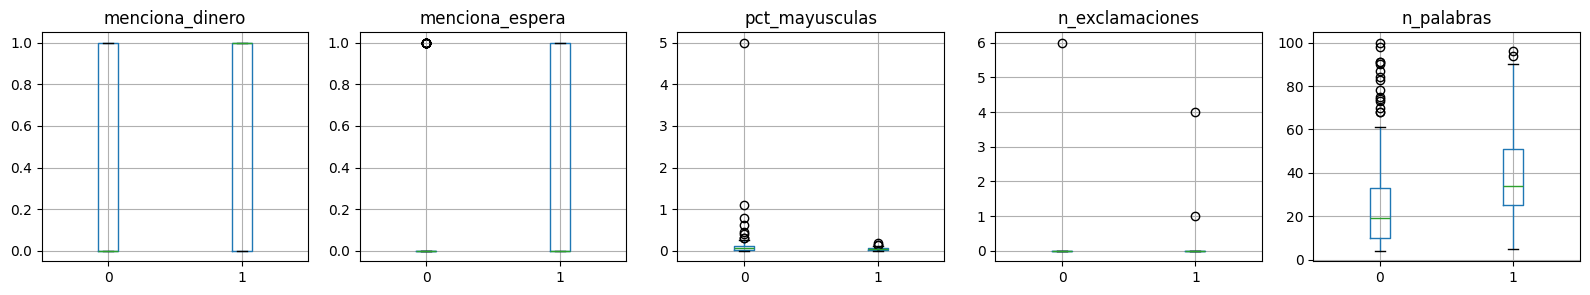

In [526]:
nuevas = ["menciona_dinero", "menciona_espera", "pct_mayusculas", "n_exclamaciones", "n_palabras"]
columnas_grafico = 5
filas_grafico = int(np.ceil(len(nuevas) / columnas_grafico))
fig, ejes = plt.subplots(filas_grafico, columnas_grafico, figsize=(16, 3.2 * filas_grafico))
for eje, col in zip(ejes.flatten(), nuevas):
    muestra[~muestra["prueba"]].boxplot(column=col, by="grave", ax=eje)
    eje.set_title(col)
    eje.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [527]:
muestra[~muestra["prueba"]].groupby("grave")[nuevas].mean().round(3)

,menciona_dinero,menciona_espera,pct_mayusculas,n_exclamaciones,n_palabras
grave,,,,,
0,0.257,0.073,0.124,0.031,25.141
1,0.610,0.305,0.046,0.085,40.508


In [528]:
## 8. Elegir variables

In [529]:
OBJETIVO = "grave"
CLASE_POSITIVA = 1 # La clase que queremos encontrar
IGNORAR = ["id", "app", "equipo", "etiquetador", "nota", "text", "fecha", "mes", "version",
           "reply", "con_respuesta", "thumbs", "negativa", "prueba", "largo", "tipo_app"] # Las variables que no vamos a usar

In [530]:
# 1 si es la clase positiva, 0 si no
y = (muestra[OBJETIVO] == CLASE_POSITIVA).astype(int)
CLASE_NEGATIVA = 0
X_original = muestra.drop(columns=[OBJETIVO] + IGNORAR)
numericas = X_original.select_dtypes(include="number").columns.tolist()
categoricas = X_original.select_dtypes(exclude="number").columns.tolist()

In [531]:
# ¿Cuáles ignoramos?
print("Objetivo:", OBJETIVO, "| clase positiva:", CLASE_POSITIVA, "| clase negativa:", CLASE_NEGATIVA)
print("Numéricas:", numericas)
print("Categóricas:", categoricas)
print("Ignoradas:", IGNORAR)

Objetivo: grave | clase positiva: 1 | clase negativa: 0
Numéricas: ['score', 'n_palabras', 'tema_fraude', 'tema_fallas_app', 'tema_plata_no_llega', 'tema_acceso_bloqueo', 'tema_cobros', 'tema_atencion', 'menciona_dinero', 'menciona_espera', 'pct_mayusculas', 'n_exclamaciones']
Categóricas: ['texto_n']
Ignoradas: ['id', 'app', 'equipo', 'etiquetador', 'nota', 'text', 'fecha', 'mes', 'version', 'reply', 'con_respuesta', 'thumbs', 'negativa', 'prueba', 'largo', 'tipo_app']


In [532]:
### 8.1 Partición temporal (entrenamiento antes de jul-2025, prueba desde jul-2025)

In [533]:
X_ent, X_pru = X_original[~muestra["prueba"]], X_original[muestra["prueba"]]
y_ent, y_pru = y[~muestra["prueba"]], y[muestra["prueba"]]
print("Entrenamiento:", X_ent.shape, "| Prueba:", X_pru.shape)

Entrenamiento: (250, 13) | Prueba: (200, 13)


In [534]:
## 9. Línea base: regla simple y decisiones triviales

In [535]:
COSTO_FN = 5 # No escalar una reseña grave
COSTO_FP = 1 # Escalar una reseña leve
REGLAS = {
    "No escalar ninguna": lambda t: t["score"] * 0,
    "Escalar todas": lambda t: t["score"] * 0 + 1,
    "Regla 1 estrella": lambda t: (t["score"] == 1).astype(int),
    "Regla temas (fraude, plata, acceso, cobros)": lambda t: (t[["tema_fraude", "tema_plata_no_llega", "tema_acceso_bloqueo", "tema_cobros"]].sum(axis=1) > 0).astype(int),
    "Regla temas + dinero": lambda t: ((t[["tema_fraude", "tema_plata_no_llega", "tema_acceso_bloqueo", "tema_cobros"]].sum(axis=1) + t["menciona_dinero"]) > 0).astype(int),
    "Regla temas + espera": lambda t: ((t[["tema_fraude", "tema_plata_no_llega", "tema_acceso_bloqueo", "tema_cobros"]].sum(axis=1) + t["menciona_espera"]) > 0).astype(int),
}

In [536]:
filas = []
for nombre, regla in REGLAS.items():
    y_pred = regla(X_ent)
    # contar aciertos y errores
    VP = ((y_pred == 1) & (y_ent == 1)).sum()
    FP = ((y_pred == 1) & (y_ent == 0)).sum()
    FN = ((y_pred == 0) & (y_ent == 1)).sum()
    VN = ((y_pred == 0) & (y_ent == 0)).sum()
    # medir
    costo = (COSTO_FN * FN + COSTO_FP * FP) / len(y_ent) * 1000
    recall = VP / (VP + FN)
    precision = VP / (VP + FP) if (VP + FP) > 0 else 0
    filas.append({
        "Decisión": nombre,
        "Costo por 1.000": costo,
        "Sensibilidad": recall,
        "Precisión": precision,
        "Escaladas": int(y_pred.sum()),
    })

linea_base = pd.DataFrame(filas).set_index("Decisión")
linea_base.round(3)

,Costo por 1.000,Sensibilidad,Precisión,Escaladas
Decisión,,,,
No escalar ninguna,1180.0,0.000,0.000,0
Escalar todas,764.0,1.000,0.236,250
Regla 1 estrella,792.0,0.831,0.249,197
"Regla temas (fraude, plata, acceso, cobros)",448.0,0.847,0.427,117
Regla temas + dinero,432.0,0.932,0.385,143
Regla temas + espera,436.0,0.881,0.413,126


In [537]:
REGLA_REFERENCIA = linea_base["Costo por 1.000"].drop(["No escalar ninguna", "Escalar todas"]).idxmin()
print("Regla de referencia (elegida en entrenamiento):", REGLA_REFERENCIA)

Regla de referencia (elegida en entrenamiento): Regla temas + dinero


In [538]:
## 10. Regresión logística: validación cruzada (paso a paso)

In [539]:
C_REGULARIZACION = 0.1 # Orange: Regularization strength C (Ridge L2)
K = 5 # Batches para el cross validation
SEMILLA = 42 # Para que el análisis salga siempre en el mismo resultado

batches = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEMILLA)
probabilidades = pd.Series(index=y_ent.index, dtype=float)

for numero, (ent, pru) in enumerate(batches.split(X_ent, y_ent), start=1):
    # separar entrenamiento y prueba
    X_e, X_p = X_ent.iloc[ent], X_ent.iloc[pru]
    y_e = y_ent.iloc[ent]
    # texto a números con TF-IDF, ajustado solo con el entrenamiento del pliegue
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
    T_e = tfidf.fit_transform(X_e["texto_n"].fillna(""))
    T_p = tfidf.transform(X_p["texto_n"].fillna(""))
    # estandarizar con la media y la DE del entrenamiento
    centro = X_e[numericas].mean()
    escala = X_e[numericas].std().replace(0, 1)
    N_e = (X_e[numericas] - centro) / escala
    N_p = (X_p[numericas] - centro) / escala
    # juntar texto y variables numéricas
    Z_e = hstack([T_e, csr_matrix(N_e.values)])
    Z_p = hstack([T_p, csr_matrix(N_p.values)])
    # entrenar
    modelo = LogisticRegression(C=C_REGULARIZACION, max_iter=1000)
    modelo.fit(Z_e, y_e)
    # predecir
    probabilidades.iloc[pru] = modelo.predict_proba(Z_p)[:, 1]

In [540]:
### 10.1 Elegir el umbral por costo

Umbral elegido: 0.12 | costo: 476.0
AUC (validación cruzada): 0.789


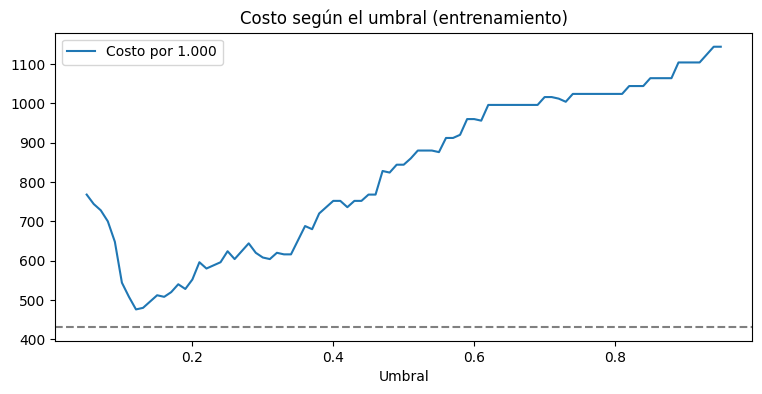

In [541]:
filas = []
for umbral in np.arange(0.05, 0.96, 0.01):
    y_pred = (probabilidades >= umbral).astype(int)
    FN = ((y_pred == 0) & (y_ent == 1)).sum()
    FP = ((y_pred == 1) & (y_ent == 0)).sum()
    filas.append({"Umbral": round(umbral, 2), "Costo por 1.000": (COSTO_FN * FN + COSTO_FP * FP) / len(y_ent) * 1000})

curva = pd.DataFrame(filas).set_index("Umbral")
UMBRAL = curva["Costo por 1.000"].idxmin()
print("Umbral elegido:", UMBRAL, "| costo:", round(curva["Costo por 1.000"].min(), 1))
print("AUC (validación cruzada):", round(roc_auc_score(y_ent, probabilidades), 3))
curva.plot(figsize=(9, 4), title="Costo según el umbral (entrenamiento)")
plt.axhline(linea_base.loc[REGLA_REFERENCIA, "Costo por 1.000"], color="gray", ls="--")
plt.show()

In [542]:
## 11. Árbol de decisión: validación cruzada (paso a paso)

In [543]:
MIN_HOJA = 5 # Orange: Min. number of instances in leaves
MIN_DIVIDIR = 10 # Orange: Do not split subsets smaller than
MAX_PROFUNDIDAD = 3 # Orange: Limit the maximal tree depth to (por defecto 100)

In [544]:
probabilidades_arbol = pd.Series(index=y_ent.index, dtype=float)

for numero, (ent, pru) in enumerate(batches.split(X_ent, y_ent), start=1):
    # separar entrenamiento y prueba
    X_e, X_p = X_ent.iloc[ent][numericas], X_ent.iloc[pru][numericas]
    y_e = y_ent.iloc[ent]
    # entrenar
    modelo = DecisionTreeClassifier(min_samples_leaf=MIN_HOJA, min_samples_split=MIN_DIVIDIR, max_depth=MAX_PROFUNDIDAD, random_state=SEMILLA)
    modelo.fit(X_e, y_e)
    # predecir
    probabilidades_arbol.iloc[pru] = modelo.predict_proba(X_p)[:, 1]

In [545]:
filas = []
for umbral in np.arange(0.05, 0.96, 0.01):
    y_pred = (probabilidades_arbol >= umbral).astype(int)
    FN = ((y_pred == 0) & (y_ent == 1)).sum()
    FP = ((y_pred == 1) & (y_ent == 0)).sum()
    filas.append({"Umbral": round(umbral, 2), "Costo por 1.000": (COSTO_FN * FN + COSTO_FP * FP) / len(y_ent) * 1000})

curva_arbol = pd.DataFrame(filas).set_index("Umbral")
UMBRAL_ARBOL = curva_arbol["Costo por 1.000"].idxmin()
print("Umbral elegido:", UMBRAL_ARBOL, "| costo:", round(curva_arbol["Costo por 1.000"].min(), 1))
print("AUC (validación cruzada):", round(roc_auc_score(y_ent, probabilidades_arbol), 3))

Umbral elegido: 0.11 | costo: 572.0
AUC (validación cruzada): 0.721


In [546]:
## 12. Evaluación en prueba (una sola vez)

In [547]:
# Regresión logística final (con todo el entrenamiento)
tfidf_final = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
T_ent = tfidf_final.fit_transform(X_ent["texto_n"].fillna(""))
T_pru = tfidf_final.transform(X_pru["texto_n"].fillna(""))
centro_final = X_ent[numericas].mean()
escala_final = X_ent[numericas].std().replace(0, 1)
Z_ent = hstack([T_ent, csr_matrix(((X_ent[numericas] - centro_final) / escala_final).values)])
Z_pru = hstack([T_pru, csr_matrix(((X_pru[numericas] - centro_final) / escala_final).values)])
modelo_final = LogisticRegression(C=C_REGULARIZACION, max_iter=1000)
modelo_final.fit(Z_ent, y_ent)

# Árbol final (con todo el entrenamiento)
arbol_final = DecisionTreeClassifier(min_samples_leaf=MIN_HOJA, min_samples_split=MIN_DIVIDIR, max_depth=MAX_PROFUNDIDAD, random_state=SEMILLA)
arbol_final.fit(X_ent[numericas], y_ent)

# Predecir en prueba
prob_log = pd.Series(modelo_final.predict_proba(Z_pru)[:, 1], index=y_pru.index)
prob_arbol = pd.Series(arbol_final.predict_proba(X_pru[numericas])[:, 1], index=y_pru.index)
decisiones = {
    "No escalar ninguna": y_pru * 0,
    "Escalar todas": y_pru * 0 + 1,
    REGLA_REFERENCIA: REGLAS[REGLA_REFERENCIA](X_pru),
    "Regresión logística": (prob_log >= UMBRAL).astype(int),
    "Árbol de decisión": (prob_arbol >= UMBRAL_ARBOL).astype(int),
}
probas = {"Regresión logística": prob_log, "Árbol de decisión": prob_arbol}

In [548]:
N_BOOT = 1000 # Remuestreos para el intervalo de confianza (brief)

def costo(y, y_pred):
    FN = ((y_pred == 0) & (y == 1)).sum()
    FP = ((y_pred == 1) & (y == 0)).sum()
    return (COSTO_FN * FN + COSTO_FP * FP) / len(y) * 1000

def tabla_prueba(mascara):
    y = y_pru[mascara]
    rng = np.random.default_rng(SEMILLA)
    muestras = [rng.integers(0, len(y), len(y)) for _ in range(N_BOOT)]
    filas = []
    for nombre, y_pred in decisiones.items():
        y_pred = y_pred[mascara]
        VP = ((y_pred == 1) & (y == 1)).sum()
        FP = ((y_pred == 1) & (y == 0)).sum()
        FN = ((y_pred == 0) & (y == 1)).sum()
        boot = [costo(y.iloc[m].values, y_pred.iloc[m].values) for m in muestras]
        filas.append({
            "Decisión": nombre,
            "Costo por 1.000": costo(y, y_pred),
            "IC 2,5%": np.percentile(boot, 2.5),
            "IC 97,5%": np.percentile(boot, 97.5),
            "Sensibilidad": VP / (VP + FN),
            "Precisión": VP / (VP + FP) if (VP + FP) > 0 else 0,
            "AUC": roc_auc_score(y, probas[nombre][mascara]) if nombre in probas else np.nan,
        })
    return pd.DataFrame(filas).set_index("Decisión").round(3)

print("Prueba:", len(y_pru), "reseñas,", y_pru.sum(), "graves")
tabla_prueba(y_pru == y_pru)

Prueba: 200 reseñas, 45 graves


,Costo por 1.000,"IC 2,5%","IC 97,5%",Sensibilidad,Precisión,AUC
Decisión,,,,,,
No escalar ninguna,1125.0,825.000,1425.0,0.000,0.000,NaN
Escalar todas,775.0,715.000,835.0,1.000,0.225,NaN
Regla temas + dinero,480.0,369.875,595.0,0.889,0.360,NaN
Regresión logística,535.0,415.000,665.0,0.867,0.336,0.792
Árbol de decisión,605.0,480.000,760.0,0.822,0.314,0.693


In [549]:
### 12.1 Solo billeteras (Brío es una billetera)

In [550]:
billeteras = muestra.loc[muestra["prueba"], "tipo_app"] == "billetera"
print("Billeteras en prueba:", billeteras.sum(), "reseñas,", y_pru[billeteras].sum(), "graves")
tabla_prueba(billeteras)

Billeteras en prueba: 79 reseñas, 22 graves


,Costo por 1.000,"IC 2,5%","IC 97,5%",Sensibilidad,Precisión,AUC
Decisión,,,,,,
No escalar ninguna,1392.405,949.367,1898.734,0.000,0.000,NaN
Escalar todas,721.519,620.253,810.127,1.000,0.278,NaN
Regla temas + dinero,481.013,316.456,696.203,0.909,0.417,NaN
Regresión logística,531.646,329.114,772.152,0.864,0.413,0.781
Árbol de decisión,759.494,518.987,1050.949,0.773,0.327,0.632


In [551]:
### 12.2 ¿El modelo le gana a la regla? (intervalo de la diferencia)

In [552]:
rng = np.random.default_rng(SEMILLA)
muestras = [rng.integers(0, len(y_pru), len(y_pru)) for _ in range(N_BOOT)]
filas = []
for modelo in ["Regresión logística", "Árbol de decisión"]:
    dif = [costo(y_pru.iloc[m].values, decisiones[modelo].iloc[m].values) - costo(y_pru.iloc[m].values, decisiones[REGLA_REFERENCIA].iloc[m].values) for m in muestras]
    filas.append({
        "Modelo": modelo,
        "Diferencia vs regla": costo(y_pru, decisiones[modelo]) - costo(y_pru, decisiones[REGLA_REFERENCIA]),
        "IC 2,5%": np.percentile(dif, 2.5),
        "IC 97,5%": np.percentile(dif, 97.5),
    })
pd.DataFrame(filas).set_index("Modelo").round(1)

,Diferencia vs regla,"IC 2,5%","IC 97,5%"
Modelo,,,
Regresión logística,55.0,-30.0,145.0
Árbol de decisión,125.0,-35.0,285.1


In [553]:
### 12.3 Matriz de confusión de la regresión logística (en costo)

In [554]:
y_pred = decisiones["Regresión logística"]
matriz = pd.crosstab(y_pru, y_pred, rownames=["Real"], colnames=["Predicho"])
print("Graves perdidas (FN):", matriz.loc[1, 0], "x", COSTO_FN, "=", matriz.loc[1, 0] * COSTO_FN, "unidades")
print("Leves escaladas (FP):", matriz.loc[0, 1], "x", COSTO_FP, "=", matriz.loc[0, 1] * COSTO_FP, "unidades")
matriz

Graves perdidas (FN): 6 x 5 = 30 unidades
Leves escaladas (FP): 77 x 1 = 77 unidades


Predicho,0,1
Real,,
0,78,77
1,6,39


In [555]:
## 13. Bosque aleatorio: validación cruzada (Random_Forest.ipynb, secciones 2 y 7.3)
from sklearn.ensemble import RandomForestClassifier

N_ARBOLES = 100 # Orange: Number of trees (por defecto 10)
MIN_DIVIDIR_BOSQUE = 5 # Orange: Do not split subsets smaller than

In [556]:
probabilidades_bosque = pd.Series(index=y_ent.index, dtype=float)

for numero, (ent, pru) in enumerate(batches.split(X_ent, y_ent), start=1):
    # separar entrenamiento y prueba (mismas variables que el árbol)
    X_e, X_p = X_ent.iloc[ent][numericas], X_ent.iloc[pru][numericas]
    y_e = y_ent.iloc[ent]
    # entrenar
    modelo = RandomForestClassifier(n_estimators=N_ARBOLES, min_samples_split=MIN_DIVIDIR_BOSQUE, random_state=SEMILLA)
    modelo.fit(X_e, y_e)
    # predecir
    probabilidades_bosque.iloc[pru] = modelo.predict_proba(X_p)[:, 1]

In [557]:
filas = []
for umbral in np.arange(0.05, 0.96, 0.01):
    y_pred = (probabilidades_bosque >= umbral).astype(int)
    FN = ((y_pred == 0) & (y_ent == 1)).sum()
    FP = ((y_pred == 1) & (y_ent == 0)).sum()
    filas.append({"Umbral": round(umbral, 2), "Costo por 1.000": (COSTO_FN * FN + COSTO_FP * FP) / len(y_ent) * 1000})

curva_bosque = pd.DataFrame(filas).set_index("Umbral")
UMBRAL_BOSQUE = curva_bosque["Costo por 1.000"].idxmin()
print("Umbral elegido:", UMBRAL_BOSQUE, "| costo:", round(curva_bosque["Costo por 1.000"].min(), 1))
print("AUC (validación cruzada):", round(roc_auc_score(y_ent, probabilidades_bosque), 3))

Umbral elegido: 0.2 | costo: 460.0
AUC (validación cruzada): 0.777


In [558]:
## 14. Boosting: validación cruzada (misma estructura que el bosque; no hay plantilla de clase)
from sklearn.ensemble import GradientBoostingClassifier

N_ARBOLES_BOOST = 100 # Orange (Gradient Boosting): Number of trees
TASA_APRENDIZAJE = 0.1 # Orange: Learning rate
MAX_PROFUNDIDAD_BOOST = 3 # Orange: Limit depth of individual trees
MIN_DIVIDIR_BOOST = 5 # Orange: Do not split subsets smaller than (igual que el bosque)

In [559]:
probabilidades_boost = pd.Series(index=y_ent.index, dtype=float)

for numero, (ent, pru) in enumerate(batches.split(X_ent, y_ent), start=1):
    # separar entrenamiento y prueba (mismas variables que el árbol y el bosque)
    X_e, X_p = X_ent.iloc[ent][numericas], X_ent.iloc[pru][numericas]
    y_e = y_ent.iloc[ent]
    # entrenar
    modelo = GradientBoostingClassifier(n_estimators=N_ARBOLES_BOOST, learning_rate=TASA_APRENDIZAJE, max_depth=MAX_PROFUNDIDAD_BOOST, min_samples_split=MIN_DIVIDIR_BOOST, random_state=SEMILLA)
    modelo.fit(X_e, y_e)
    # predecir
    probabilidades_boost.iloc[pru] = modelo.predict_proba(X_p)[:, 1]

In [560]:
filas = []
for umbral in np.arange(0.05, 0.96, 0.01):
    y_pred = (probabilidades_boost >= umbral).astype(int)
    FN = ((y_pred == 0) & (y_ent == 1)).sum()
    FP = ((y_pred == 1) & (y_ent == 0)).sum()
    filas.append({"Umbral": round(umbral, 2), "Costo por 1.000": (COSTO_FN * FN + COSTO_FP * FP) / len(y_ent) * 1000})

curva_boost = pd.DataFrame(filas).set_index("Umbral")
UMBRAL_BOOST = curva_boost["Costo por 1.000"].idxmin()
print("Umbral elegido:", UMBRAL_BOOST, "| costo:", round(curva_boost["Costo por 1.000"].min(), 1))
print("AUC (validación cruzada):", round(roc_auc_score(y_ent, probabilidades_boost), 3))

Umbral elegido: 0.09 | costo: 488.0
AUC (validación cruzada): 0.725


In [561]:
## 15. Evaluación en prueba de los ensambles (una sola vez)
# Bosque y boosting finales con todo el entrenamiento (Random_Forest.ipynb, sección 9)
bosque_final = RandomForestClassifier(n_estimators=N_ARBOLES, min_samples_split=MIN_DIVIDIR_BOSQUE, random_state=SEMILLA)
bosque_final.fit(X_ent[numericas], y_ent)
boost_final = GradientBoostingClassifier(n_estimators=N_ARBOLES_BOOST, learning_rate=TASA_APRENDIZAJE, max_depth=MAX_PROFUNDIDAD_BOOST, min_samples_split=MIN_DIVIDIR_BOOST, random_state=SEMILLA)
boost_final.fit(X_ent[numericas], y_ent)

# Predecir en prueba con el umbral elegido en validación cruzada
prob_bosque = pd.Series(bosque_final.predict_proba(X_pru[numericas])[:, 1], index=y_pru.index)
prob_boost = pd.Series(boost_final.predict_proba(X_pru[numericas])[:, 1], index=y_pru.index)
decisiones["Bosque aleatorio"] = (prob_bosque >= UMBRAL_BOSQUE).astype(int)
decisiones["Boosting"] = (prob_boost >= UMBRAL_BOOST).astype(int)
probas["Bosque aleatorio"] = prob_bosque
probas["Boosting"] = prob_boost

print("Prueba:", len(y_pru), "reseñas,", y_pru.sum(), "graves")
tabla_prueba(y_pru == y_pru)

Prueba: 200 reseñas, 45 graves


,Costo por 1.000,"IC 2,5%","IC 97,5%",Sensibilidad,Precisión,AUC
Decisión,,,,,,
No escalar ninguna,1125.0,825.000,1425.000,0.000,0.000,NaN
Escalar todas,775.0,715.000,835.000,1.000,0.225,NaN
Regla temas + dinero,480.0,369.875,595.000,0.889,0.360,NaN
Regresión logística,535.0,415.000,665.000,0.867,0.336,0.792
Árbol de decisión,605.0,480.000,760.000,0.822,0.314,0.693
Bosque aleatorio,575.0,410.000,745.125,0.733,0.375,0.780
Boosting,585.0,430.000,755.000,0.733,0.367,0.758


In [562]:
### 15.1 Solo billeteras (Brío es una billetera)
tabla_prueba(billeteras)

,Costo por 1.000,"IC 2,5%","IC 97,5%",Sensibilidad,Precisión,AUC
Decisión,,,,,,
No escalar ninguna,1392.405,949.367,1898.734,0.000,0.000,NaN
Escalar todas,721.519,620.253,810.127,1.000,0.278,NaN
Regla temas + dinero,481.013,316.456,696.203,0.909,0.417,NaN
Regresión logística,531.646,329.114,772.152,0.864,0.413,0.781
Árbol de decisión,759.494,518.987,1050.949,0.773,0.327,0.632
Bosque aleatorio,645.570,367.089,987.342,0.727,0.432,0.754
Boosting,658.228,392.405,1000.000,0.727,0.421,0.734


In [563]:
### 15.2 ¿Algún modelo le gana a la regla? (intervalo de la diferencia, mismas muestras)
rng = np.random.default_rng(SEMILLA)
muestras = [rng.integers(0, len(y_pru), len(y_pru)) for _ in range(N_BOOT)]
filas = []
for modelo in ["Regresión logística", "Árbol de decisión", "Bosque aleatorio", "Boosting"]:
    dif = [costo(y_pru.iloc[m].values, decisiones[modelo].iloc[m].values) - costo(y_pru.iloc[m].values, decisiones[REGLA_REFERENCIA].iloc[m].values) for m in muestras]
    filas.append({
        "Modelo": modelo,
        "Diferencia vs regla": costo(y_pru, decisiones[modelo]) - costo(y_pru, decisiones[REGLA_REFERENCIA]),
        "IC 2,5%": np.percentile(dif, 2.5),
        "IC 97,5%": np.percentile(dif, 97.5),
    })
pd.DataFrame(filas).set_index("Modelo").round(1)

,Diferencia vs regla,"IC 2,5%","IC 97,5%"
Modelo,,,
Regresión logística,55.0,-30.0,145.0
Árbol de decisión,125.0,-35.0,285.1
Bosque aleatorio,95.0,-65.0,255.0
Boosting,105.0,-25.0,250.0


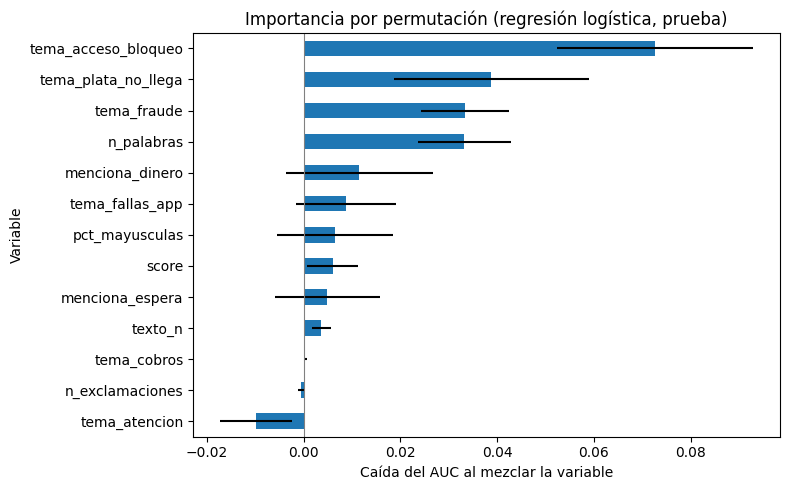

,Caída del AUC,DE,Aumento del costo
Variable,,,
tema_acceso_bloqueo,0.0727,0.0203,160.0000
tema_plata_no_llega,0.0388,0.0202,31.8333
tema_fraude,0.0334,0.0091,29.5000
n_palabras,0.0332,0.0096,4.8333
menciona_dinero,0.0115,0.0152,6.6667
tema_fallas_app,0.0087,0.0103,-20.8333
pct_mayusculas,0.0065,0.0120,-4.3333
score,0.0060,0.0053,9.3333
menciona_espera,0.0049,0.0109,-2.6667


In [564]:
## 16. Qué explica el modelo: importancia por permutación (regresión logística)
# No está en las plantillas: lo pide el brief ("un gráfico de importancia por permutación o de SHAP")
N_REPETICIONES = 30 # Veces que se mezcla cada variable

def probabilidad_log(X):
    # misma preparación que en la sección 12: TF-IDF + numéricas estandarizadas
    T = tfidf_final.transform(X["texto_n"].fillna(""))
    N = (X[numericas] - centro_final) / escala_final
    return modelo_final.predict_proba(hstack([T, csr_matrix(N.values)]))[:, 1]

auc_base = roc_auc_score(y_pru, probabilidad_log(X_pru))
costo_base = costo(y_pru, (probabilidad_log(X_pru) >= UMBRAL).astype(int))
rng = np.random.default_rng(SEMILLA)

filas = []
for variable in ["texto_n"] + numericas:
    caidas_auc = []
    subidas_costo = []
    for _ in range(N_REPETICIONES):
        # mezclar una sola variable y dejar las demás igual
        X_mezcla = X_pru.copy()
        X_mezcla[variable] = rng.permutation(X_mezcla[variable].values)
        p = probabilidad_log(X_mezcla)
        caidas_auc.append(auc_base - roc_auc_score(y_pru, p))
        subidas_costo.append(costo(y_pru, (p >= UMBRAL).astype(int)) - costo_base)
    filas.append({
        "Variable": variable,
        "Caída del AUC": np.mean(caidas_auc),
        "DE": np.std(caidas_auc),
        "Aumento del costo": np.mean(subidas_costo),
    })

importancia = pd.DataFrame(filas).set_index("Variable").sort_values("Caída del AUC")
importancia["Caída del AUC"].plot.barh(xerr=importancia["DE"], figsize=(8, 5), title="Importancia por permutación (regresión logística, prueba)")
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("Caída del AUC al mezclar la variable")
plt.tight_layout()
plt.show()
importancia.sort_values("Caída del AUC", ascending=False).round(4)

In [565]:
### 16.1 Palabras que más pesan (coeficientes de la regresión logística)
palabras = tfidf_final.get_feature_names_out()
pesos = pd.DataFrame({"Peso": modelo_final.coef_[0][:len(palabras)]}, index=palabras)
print("Empujan hacia GRAVE:")
print(pesos.sort_values("Peso", ascending=False).head(15).round(3))
print("\nEmpujan hacia LEVE:")
print(pesos.sort_values("Peso").head(10).round(3))

Empujan hacia GRAVE:
             Peso
no          0.078
he          0.073
sirve la    0.063
lo          0.062
ni          0.060
la          0.059
en          0.059
pasos       0.059
en la       0.057
servicio    0.056
clave       0.055
deja        0.053
de          0.050
contrasena  0.049
sin poder   0.044

Empujan hacia LEVE:
            Peso
muy       -0.077
para      -0.071
cuando    -0.053
problema  -0.051
que se    -0.051
al        -0.045
transfiya -0.042
como      -0.040
mucho     -0.039
lenta     -0.038


In [566]:
## 17. Análisis de errores (regla y regresión logística, prueba)
# No está en las plantillas: lo pide el brief ("qué tipo de reseña escala sin necesidad y cuál deja pasar")
errores = muestra.loc[muestra["prueba"], ["app", "tipo_app", "equipo", "n_palabras", "text"] + TEMAS + ["menciona_dinero"]].copy()
errores["grave"] = y_pru
errores["prob_log"] = prob_log.round(2)
for nombre, columna in [(REGLA_REFERENCIA, "error_regla"), ("Regresión logística", "error_log")]:
    d = decisiones[nombre]
    errores[columna] = np.select([(y_pru == 1) & (d == 1), (y_pru == 0) & (d == 1), (y_pru == 1) & (d == 0)], ["VP", "FP", "FN"], "VN")

pd.crosstab(errores["error_regla"], errores["error_log"], rownames=["Regla"], colnames=["Logística"])

Logística,FN,FP,VN,VP
Regla,,,,
FN,4,0,0,1
FP,0,69,2,0
VN,0,8,76,0
VP,2,0,0,38


In [567]:
### 17.1 Qué deja pasar: graves no escaladas (FN)
graves = errores[errores["grave"] == 1]
display(pd.crosstab(graves["equipo"], graves["error_regla"], rownames=["Equipo"], colnames=["Regla"]))
errores.loc[errores["error_regla"] == "FN", ["equipo", "prob_log", "error_log", "text"]]

Regla,FN,VP
Equipo,,
acceso_identidad,4,20
cobros_tarifas,0,4
otro,0,2
pagos_transferencias,1,7
seguridad_fraude,0,3
tecnologia_app,0,4


,equipo,prob_log,error_log,text
25,acceso_identidad,0.11,FN,yo tengo problemas con la aplicación porque no...
109,acceso_identidad,0.13,VP,"muy complicada, no he podido acceder a la apli..."
169,pagos_transferencias,0.10,FN,no recibe tranferencias x ninguna llave
382,acceso_identidad,0.07,FN,le doy este puntaje porque tengo un producto c...
438,acceso_identidad,0.09,FN,el servicio actual del nuevo Bancolombia parec...


In [568]:
### 17.2 Qué escala sin necesidad: leves escaladas (FP)
fp = errores[errores["error_regla"] == "FP"]
print("Leves escaladas por la regla:", len(fp), "| costo:", len(fp) * COSTO_FP, "unidades de", int(costo(y_pru, decisiones[REGLA_REFERENCIA]) * len(y_pru) / 1000))
print("Escaladas SOLO por menciona_dinero (sin ningún tema):", ((fp[["tema_fraude", "tema_plata_no_llega", "tema_acceso_bloqueo", "tema_cobros"]].sum(axis=1) == 0)).sum())
print("\n% de las FP con cada señal:")
print(fp[TEMAS + ["menciona_dinero"]].mean().round(2).sort_values(ascending=False))
fp.sample(10, random_state=SEMILLA)[["tema_acceso_bloqueo", "menciona_dinero", "text"]]

Leves escaladas por la regla: 71 | costo: 71 unidades de 96
Escaladas SOLO por menciona_dinero (sin ningún tema): 14

% de las FP con cada señal:
tema_acceso_bloqueo    0.55
menciona_dinero        0.54
tema_fallas_app        0.49
tema_plata_no_llega    0.30
tema_atencion          0.06
tema_fraude            0.01
tema_cobros            0.01
dtype: float64


,tema_acceso_bloqueo,menciona_dinero,text
165,1,0,"no puedo inscribir la clave dinámica, mi celul..."
7,0,1,si todos los comentarios que lei son 1 o 2 est...
332,1,1,"una buena aplicación, pero la aplicación apare..."
38,0,1,"la aplicación presenta fallas, no me permite t..."
351,0,1,peor aplicación para tener plata no pueden ten...
147,1,0,la app no me deja ingresar correctamente y cad...
88,1,0,me ilusione pensando q alfin tendría nequi med...
280,1,1,problemitas para girar mi dinero por culpa de ...
314,1,0,"la última actualización no permite ingresar, s..."
106,0,1,"Terrible la experiencia con esta aplicación, e..."


In [569]:
## 18. Enrutamiento a equipos: regla de temas frente a clasificador multiclase
# No está en las plantillas: lo pide el brief ("¿con reglas o con un clasificador de varias clases entrenado con su etiqueta equipo? Reporten cuántas reseñas manda al equipo equivocado")
EQUIPO_DE_TEMA = {
    "tema_fraude": "seguridad_fraude",
    "tema_plata_no_llega": "pagos_transferencias",
    "tema_cobros": "cobros_tarifas",
    "tema_acceso_bloqueo": "acceso_identidad",
    "tema_fallas_app": "tecnologia_app",
    "tema_atencion": "servicio_cliente",
}
# Si una reseña toca varios temas, va al equipo del tema más grave: primero lo que pone plata en riesgo
ORDEN_TEMAS = ["tema_fraude", "tema_plata_no_llega", "tema_cobros", "tema_acceso_bloqueo", "tema_fallas_app", "tema_atencion"]

def enrutar(tabla, orden):
    # cada reseña va al equipo del primer tema que tenga, según el orden; sin tema va a "otro"
    equipo = pd.Series("otro", index=tabla.index)
    for tema in reversed(orden):
        equipo[tabla[tema] == 1] = EQUIPO_DE_TEMA[tema]
    return equipo

graves_ent = muestra[(muestra["grave"] == 1) & ~muestra["prueba"]]
graves_pru = muestra[(muestra["grave"] == 1) & muestra["prueba"]]
print("Graves con equipo: entrenamiento", len(graves_ent), "| prueba", len(graves_pru))
pd.crosstab(muestra.loc[muestra["grave"] == 1, "equipo"], muestra.loc[muestra["grave"] == 1, "prueba"], rownames=["Equipo"], colnames=["Prueba"])

Graves con equipo: entrenamiento 59 | prueba 45


Prueba,False,True
Equipo,,
acceso_identidad,25,24
cobros_tarifas,4,4
otro,0,2
pagos_transferencias,8,8
seguridad_fraude,5,3
tecnologia_app,17,4


In [570]:
### 18.1 Clasificador multiclase (misma logística, objetivo = equipo) y comparación en entrenamiento
batches_equipo = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEMILLA)
pred_multiclase = pd.Series(index=graves_ent.index, dtype=object)

for numero, (ent, pru) in enumerate(batches_equipo.split(graves_ent, graves_ent["equipo"]), start=1):
    # separar entrenamiento y prueba
    X_e, X_p = graves_ent.iloc[ent], graves_ent.iloc[pru]
    # texto a números con TF-IDF, ajustado solo con el entrenamiento del pliegue
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
    T_e = tfidf.fit_transform(X_e["texto_n"].fillna(""))
    T_p = tfidf.transform(X_p["texto_n"].fillna(""))
    # estandarizar con la media y la DE del entrenamiento
    centro = X_e[numericas].mean()
    escala = X_e[numericas].std().replace(0, 1)
    Z_e = hstack([T_e, csr_matrix(((X_e[numericas] - centro) / escala).values)])
    Z_p = hstack([T_p, csr_matrix(((X_p[numericas] - centro) / escala).values)])
    # entrenar y predecir
    modelo = LogisticRegression(C=C_REGULARIZACION, max_iter=2000)
    modelo.fit(Z_e, X_e["equipo"])
    pred_multiclase.iloc[pru] = modelo.predict(Z_p)

MAYORIA = graves_ent["equipo"].value_counts().idxmax()
pd.DataFrame({
    "Enrutamiento": ["Todo al equipo más común (" + MAYORIA + ")", "Regla de temas", "Clasificador multiclase"],
    "Equipo equivocado": [(graves_ent["equipo"] != MAYORIA).sum(), (enrutar(graves_ent, ORDEN_TEMAS) != graves_ent["equipo"]).sum(), (pred_multiclase != graves_ent["equipo"]).sum()],
    "De": len(graves_ent),
}).set_index("Enrutamiento")

,Equipo equivocado,De
Enrutamiento,,
Todo al equipo más común (acceso_identidad),34,59
Regla de temas,33,59
Clasificador multiclase,29,59


In [571]:
### 18.2 Enrutamiento en prueba: ¿cuántas graves van al equipo equivocado?
tfidf_equipo = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
T_e = tfidf_equipo.fit_transform(graves_ent["texto_n"].fillna(""))
T_p = tfidf_equipo.transform(graves_pru["texto_n"].fillna(""))
centro_equipo = graves_ent[numericas].mean()
escala_equipo = graves_ent[numericas].std().replace(0, 1)
modelo_equipo = LogisticRegression(C=C_REGULARIZACION, max_iter=2000)
modelo_equipo.fit(hstack([T_e, csr_matrix(((graves_ent[numericas] - centro_equipo) / escala_equipo).values)]), graves_ent["equipo"])

rutas = {
    "Todo al equipo más común (" + MAYORIA + ")": pd.Series(MAYORIA, index=graves_pru.index),
    "Regla de temas": enrutar(graves_pru, ORDEN_TEMAS),
    "Clasificador multiclase": pd.Series(modelo_equipo.predict(hstack([T_p, csr_matrix(((graves_pru[numericas] - centro_equipo) / escala_equipo).values)])), index=graves_pru.index),
}
escaladas = REGLAS[REGLA_REFERENCIA](graves_pru) == 1   # las graves que la regla de gravedad sí escala
filas = []
for nombre, ruta in rutas.items():
    filas.append({
        "Enrutamiento": nombre,
        "Equipo equivocado (45 graves)": (ruta != graves_pru["equipo"]).sum(),
        "% equivocado": (ruta != graves_pru["equipo"]).mean(),
        "Equipo equivocado (graves escaladas por la regla)": (ruta[escaladas] != graves_pru.loc[escaladas, "equipo"]).sum(),
        "De": escaladas.sum(),
    })
display(pd.DataFrame(filas).set_index("Enrutamiento").round(3))
pd.crosstab(graves_pru["equipo"], rutas["Regla de temas"], rownames=["Equipo real"], colnames=["Regla de temas"])

,Equipo equivocado (45 graves),% equivocado,Equipo equivocado (graves escaladas por la regla),De
Enrutamiento,,,,
Todo al equipo más común (acceso_identidad),21,0.467,20,40
Regla de temas,21,0.467,16,40
Clasificador multiclase,18,0.400,17,40


Regla de temas,acceso_identidad,cobros_tarifas,otro,pagos_transferencias,seguridad_fraude,tecnologia_app
Equipo real,,,,,,
acceso_identidad,15,0,4,3,0,2
cobros_tarifas,0,2,0,2,0,0
otro,0,0,0,2,0,0
pagos_transferencias,0,1,1,5,1,0
seguridad_fraude,0,0,0,1,2,0
tecnologia_app,0,0,0,4,0,0


In [572]:
## 19. Descubrimiento: K-Means de las apps según los temas de sus reseñas negativas (KMeans.ipynb)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

ETIQUETA = "app" # Columna que nombra cada fila (no entra al modelo)
K_MIN = 2 # Menor número de grupos que se prueba
K_MAX = 8 # Mayor número de grupos que se prueba (hay 15 apps)
N_INICIOS = 10 # Orange: Re-runs
MAX_ITER = 300 # Orange: Maximum iterations

# perfil de cada app: % de sus reseñas negativas que toca cada tema (todo el periodo del panel)
panel["n_negativas"] = panel["n_resenas"] * panel["pct_negativas"]
por_app = panel.groupby(ETIQUETA)[["n_negativas"] + ["neg_" + t.replace("tema_", "") for t in TEMAS]].sum()
X = pd.DataFrame(index=por_app.index)
for tema in TEMAS:
    X[tema.replace("tema_", "pct_")] = por_app["neg_" + tema.replace("tema_", "")] / por_app["n_negativas"]
tipo = neg.groupby(ETIQUETA)["tipo_app"].first()

# Z-score (sección 6.3)
medias = X.mean()
desviaciones = X.std()
Z = (X - medias) / desviaciones
X.round(3).assign(tipo_app=tipo)

,pct_fraude,pct_fallas_app,pct_plata_no_llega,pct_acceso_bloqueo,pct_cobros,pct_atencion,tipo_app
app,,,,,,,
agrario,0.008,0.378,0.134,0.412,0.014,0.084,banco tradicional
avvillas,0.020,0.433,0.139,0.369,0.022,0.056,banco tradicional
bancolombia,0.019,0.433,0.254,0.326,0.012,0.042,banco tradicional
bbva,0.018,0.527,0.224,0.288,0.020,0.076,banco tradicional
bogota,0.034,0.396,0.207,0.195,0.037,0.055,banco tradicional
cajasocial,0.014,0.464,0.176,0.279,0.008,0.032,banco tradicional
colpatria,0.022,0.446,0.191,0.271,0.044,0.075,banco tradicional
dale,0.053,0.360,0.249,0.365,0.012,0.113,billetera
daviplata,0.047,0.428,0.255,0.310,0.005,0.132,billetera


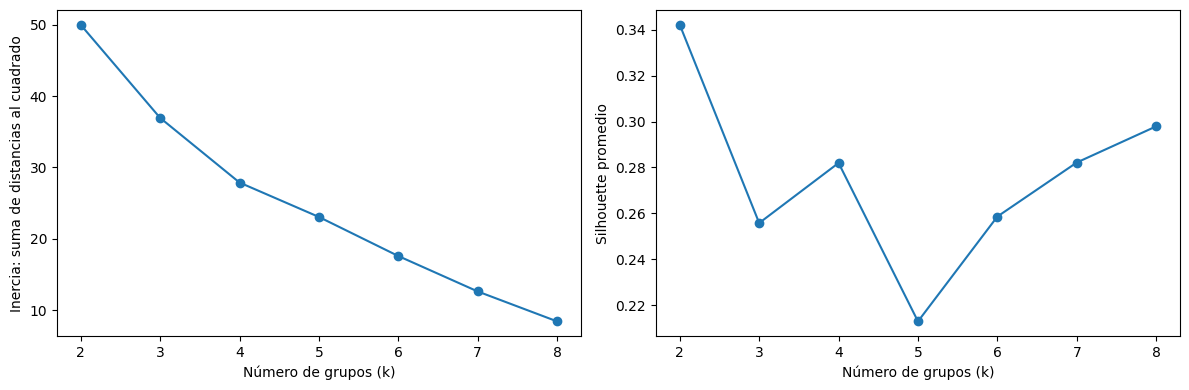

,k,inercia,silhouette
0,2,49.974,0.342
1,3,36.937,0.256
2,4,27.878,0.282
3,5,23.057,0.213
4,6,17.583,0.259
5,7,12.621,0.282
6,8,8.426,0.298


In [573]:
### 19.1 ¿Cuántos grupos? Codo y silhouette
valores_k = list(range(K_MIN, K_MAX + 1))
inercias = []
siluetas = []
for k in valores_k:
    modelo = KMeans(n_clusters=k, n_init=N_INICIOS, max_iter=MAX_ITER, random_state=SEMILLA)
    modelo.fit(Z)
    # distancia al cuadrado de cada fila al centro de su grupo
    centro_de_cada_fila = modelo.cluster_centers_[modelo.labels_]
    distancias = ((Z.values - centro_de_cada_fila) ** 2).sum(axis=1)
    inercias.append(distancias.sum())
    siluetas.append(silhouette_score(Z, modelo.labels_))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(valores_k, inercias, marker="o")
ejes[0].set_xlabel("Número de grupos (k)")
ejes[0].set_ylabel("Inercia: suma de distancias al cuadrado")
ejes[1].plot(valores_k, siluetas, marker="o")
ejes[1].set_xlabel("Número de grupos (k)")
ejes[1].set_ylabel("Silhouette promedio")
plt.tight_layout()
plt.show()
pd.DataFrame({"k": valores_k, "inercia": inercias, "silhouette": siluetas}).round(3)

In [574]:
### 19.2 Modelo final y perfil de cada grupo
K_ELEGIDO = 2 # Mayor silhouette (0,342); el codo no es claro

modelo_kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=N_INICIOS, max_iter=MAX_ITER, random_state=SEMILLA)
modelo_kmeans.fit(Z)
segmentos = pd.DataFrame({"tipo_app": tipo.reindex(X.index)})
segmentos["Grupo"] = "C" + (modelo_kmeans.labels_ + 1).astype(str)
segmentos["Silhouette"] = silhouette_samples(Z, modelo_kmeans.labels_)
segmentos["Negativas"] = por_app["n_negativas"].round()
print("Silhouette promedio:", round(segmentos["Silhouette"].mean(), 3))
display(segmentos.sort_values(["Grupo", "Silhouette"]).round(3))

# promedio de cada grupo en unidades originales y en z-score
perfil = X.groupby(segmentos["Grupo"]).mean()
perfil["Apps"] = segmentos.groupby("Grupo").size()
display(perfil.round(3))
Z.groupby(segmentos["Grupo"]).mean().round(2)

Silhouette promedio: 0.342


,tipo_app,Grupo,Silhouette,Negativas
app,,,,
nequi,billetera,C1,0.201,42490.0
agrario,banco tradicional,C1,0.244,500.0
bancolombia,banco tradicional,C1,0.314,8969.0
bogota,banco tradicional,C1,0.327,5934.0
colpatria,banco tradicional,C1,0.361,2560.0
falabella,banco tradicional,C1,0.382,1439.0
bbva,banco tradicional,C1,0.400,8719.0
avvillas,banco tradicional,C1,0.407,2785.0
davivienda,banco tradicional,C1,0.436,35670.0


,pct_fraude,pct_fallas_app,pct_plata_no_llega,pct_acceso_bloqueo,pct_cobros,pct_atencion,Apps
Grupo,,,,,,,
C1,0.020,0.449,0.170,0.285,0.022,0.059,11
C2,0.055,0.337,0.226,0.391,0.022,0.139,4


,pct_fraude,pct_fallas_app,pct_plata_no_llega,pct_acceso_bloqueo,pct_cobros,pct_atencion
Grupo,,,,,,
C1,-0.51,0.35,-0.26,-0.35,0.01,-0.50
C2,1.39,-0.97,0.73,0.97,-0.02,1.37


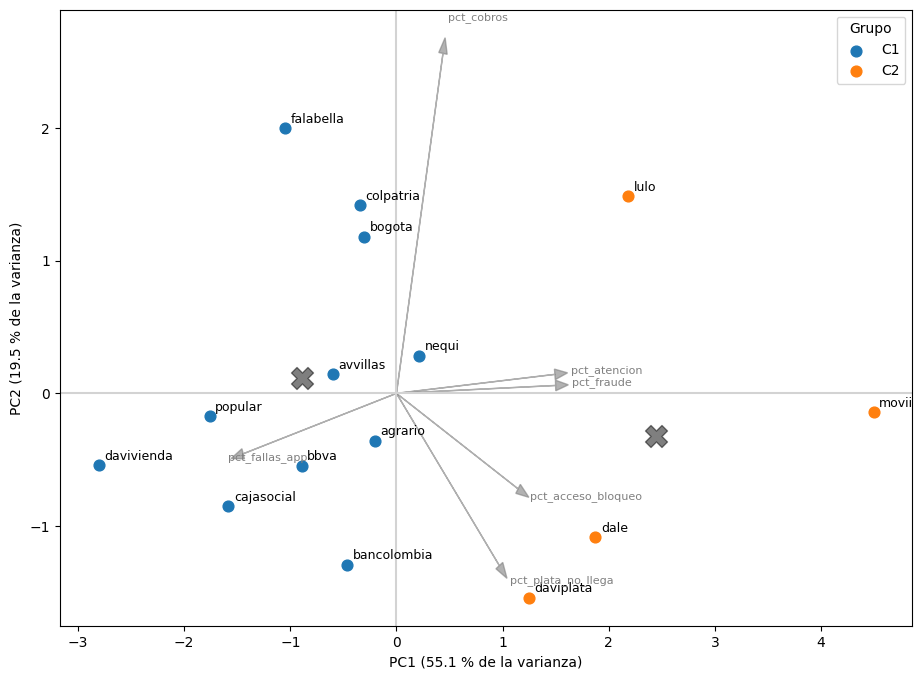

,PC1,PC2
pct_fraude,0.500,0.020
pct_fallas_app,-0.481,-0.152
pct_plata_no_llega,0.323,-0.433
pct_acceso_bloqueo,0.382,-0.240
pct_cobros,0.146,0.854
pct_atencion,0.497,0.048


In [575]:
### 19.3 Los grupos en el plano de PC1 y PC2 (APORTE FINAL PCA)
pca = PCA()
componentes = pca.fit_transform(Z)
nombres_pc = []
for i in range(componentes.shape[1]):
    nombres_pc.append("PC" + str(i + 1))
componentes = pd.DataFrame(componentes, columns=nombres_pc, index=Z.index)
varianza = pd.DataFrame({"varianza explicada": pca.explained_variance_ratio_, "acumulada": pca.explained_variance_ratio_.cumsum()}, index=nombres_pc)
cargas = pd.DataFrame(pca.components_.T, index=Z.columns, columns=nombres_pc)

plt.figure(figsize=(11, 8))
for grupo in sorted(segmentos["Grupo"].unique()):
    filas_grupo = componentes[segmentos["Grupo"] == grupo]
    plt.scatter(filas_grupo["PC1"], filas_grupo["PC2"], s=60, label=grupo, zorder=3)
    # centro del grupo
    plt.scatter(filas_grupo["PC1"].mean(), filas_grupo["PC2"].mean(), marker="X", s=250, color="black", alpha=0.5)
# nombre de cada app
for i in componentes.index:
    plt.annotate(i, (componentes.loc[i, "PC1"], componentes.loc[i, "PC2"]), fontsize=9, xytext=(4, 4), textcoords="offset points")
# flecha de cada variable
largo = 3
for variable in cargas.index:
    x = cargas.loc[variable, "PC1"] * largo
    y = cargas.loc[variable, "PC2"] * largo
    plt.arrow(0, 0, x, y, color="gray", alpha=0.6, head_width=0.08)
    plt.text(x * 1.1, y * 1.1, variable, color="gray", fontsize=8)
plt.axhline(0, color="lightgray")
plt.axvline(0, color="lightgray")
plt.xlabel("PC1 (" + str(round(varianza.loc["PC1", "varianza explicada"] * 100, 1)) + " % de la varianza)")
plt.ylabel("PC2 (" + str(round(varianza.loc["PC2", "varianza explicada"] * 100, 1)) + " % de la varianza)")
plt.legend(title="Grupo")
plt.show()
cargas[["PC1", "PC2"]].round(3)

In [576]:
## 20. Despliegue: reseñas graves por día y por equipo para Brío
# No está en las plantillas: lo pide el brief ("apliquen el clasificador a todas las reseñas negativas recientes de las billeteras y estimen cuántas graves por día recibiría una billetera de un tamaño que ustedes definan y justifiquen")
DESDE_RECIENTE = "2026-01-01" # Reseñas recientes: todo 2026 (ene-jul)
USUARIOS_COMPETIDORES = {"nequi": 27.0, "daviplata": 18.7} # Millones de usuarios (brief: Valora Analitik 2025 y 2026)
USUARIOS_BRIO = 5.0 # Supuesto: millones de usuarios de Brío en su primer año

# 1. Aplicar la regla y el enrutamiento a las negativas recientes de billeteras
recientes = preparar(neg[(neg["tipo_app"] == "billetera") & (pd.to_datetime(neg["fecha"]) >= DESDE_RECIENTE)])
recientes["escalar"] = REGLAS[REGLA_REFERENCIA](recientes)
recientes["equipo_sugerido"] = enrutar(recientes, ORDEN_TEMAS)
DIAS = (pd.to_datetime(recientes["fecha"]).max().normalize() - pd.Timestamp(DESDE_RECIENTE)).days + 1

volumen_app = recientes.groupby("app").agg(negativas=("id", "count"), escaladas=("escalar", "sum"))
volumen_app["Negativas por día"] = volumen_app["negativas"] / DIAS
volumen_app["Escaladas por día"] = volumen_app["escaladas"] / DIAS
volumen_app["% escaladas"] = volumen_app["escaladas"] / volumen_app["negativas"]
volumen_app["Usuarios (millones)"] = pd.Series(USUARIOS_COMPETIDORES)
volumen_app["Negativas por día por millón"] = volumen_app["Negativas por día"] / volumen_app["Usuarios (millones)"]
print("Días:", DIAS)
display(volumen_app.round(2))

# 2. Llevarlo al tamaño de Brío
NEG_POR_MILLON = volumen_app["Negativas por día por millón"].mean()   # promedio de Nequi y DaviPlata
PCT_ESCALAR = recientes["escalar"].mean()
y_b, d_b = y_pru[billeteras], decisiones[REGLA_REFERENCIA][billeteras]
PRECISION_REGLA = ((d_b == 1) & (y_b == 1)).sum() / (d_b == 1).sum()      # billeteras, prueba
SENSIBILIDAD_REGLA = ((d_b == 1) & (y_b == 1)).sum() / (y_b == 1).sum()   # billeteras, prueba

negativas_dia = USUARIOS_BRIO * NEG_POR_MILLON
escaladas_dia = negativas_dia * PCT_ESCALAR
graves_detectadas_dia = escaladas_dia * PRECISION_REGLA
graves_dia = graves_detectadas_dia / SENSIBILIDAD_REGLA
pd.DataFrame({
    "Valor": [USUARIOS_BRIO, NEG_POR_MILLON, negativas_dia, PCT_ESCALAR, escaladas_dia, PRECISION_REGLA, graves_detectadas_dia, SENSIBILIDAD_REGLA, graves_dia],
}, index=["Usuarios de Brío (millones)", "Negativas por día por millón", "Negativas por día", "% que escala la regla", "Escaladas por día",
          "Precisión de la regla (billeteras)", "Graves detectadas por día", "Sensibilidad de la regla (billeteras)", "Graves totales por día (estimadas)"]).round(2)

Días: 212


,negativas,escaladas,Negativas por día,Escaladas por día,% escaladas,Usuarios (millones),Negativas por día por millón
app,,,,,,,
dale,359,184,1.69,0.87,0.51,NaN,NaN
daviplata,5454,3201,25.73,15.10,0.59,18.7,1.38
movii,373,212,1.76,1.00,0.57,NaN,NaN
nequi,4419,2265,20.84,10.68,0.51,27.0,0.77


,Valor
Usuarios de Brío (millones),5.00
Negativas por día por millón,1.07
Negativas por día,5.37
% que escala la regla,0.55
Escaladas por día,2.97
Precisión de la regla (billeteras),0.42
Graves detectadas por día,1.24
Sensibilidad de la regla (billeteras),0.91
Graves totales por día (estimadas),1.36


In [577]:
### 20.1 Por equipo: cuántas escaladas y graves recibe cada uno por día
reparto = recientes.loc[recientes["escalar"] == 1, "equipo_sugerido"].value_counts(normalize=True)
por_equipo = pd.DataFrame({"% de las escaladas": reparto})
por_equipo["Escaladas por día (Brío)"] = por_equipo["% de las escaladas"] * escaladas_dia
por_equipo["Graves por día (Brío)"] = por_equipo["Escaladas por día (Brío)"] * PRECISION_REGLA
por_equipo.round(2)

,% de las escaladas,Escaladas por día (Brío),Graves por día (Brío)
equipo_sugerido,,,
acceso_identidad,0.39,1.16,0.49
pagos_transferencias,0.37,1.10,0.46
tecnologia_app,0.08,0.24,0.10
otro,0.08,0.24,0.10
seguridad_fraude,0.06,0.16,0.07
servicio_cliente,0.01,0.03,0.01
cobros_tarifas,0.01,0.03,0.01


In [578]:
### 20.2 Pronóstico mensual de reseñas escaladas (billeteras) frente a líneas base
# No está en las plantillas: lo pide el brief (pronóstico mensual con intervalo frente a
# mes anterior, promedio de 3 meses y mismo mes del año anterior, con su error en los últimos meses)
from sklearn.linear_model import LinearRegression
N_MESES_PRUEBA = 6 # Últimos meses de la serie: no se usan para ajustar

# serie mensual: reseñas negativas de billeteras que la regla escala
todas_billeteras = preparar(neg[neg["tipo_app"] == "billetera"])
todas_billeteras["escalar"] = REGLAS[REGLA_REFERENCIA](todas_billeteras)
todas_billeteras["mes"] = pd.to_datetime(todas_billeteras["fecha"]).dt.to_period("M")
serie = pd.DataFrame({"real": todas_billeteras.groupby("mes")["escalar"].sum()})

# líneas base
serie["mes_anterior"] = serie["real"].shift(1)
serie["promedio_3_meses"] = (serie["real"].shift(1) + serie["real"].shift(2) + serie["real"].shift(3)) / 3
serie["mismo_mes_año_anterior"] = serie["real"].shift(12)

# rezagos para la regresión
LAGS = ["lag1", "lag2", "lag3"]
for i, lag in enumerate(LAGS, start=1):
    serie[lag] = serie["real"].shift(i)

# regresión lineal con los 3 meses anteriores, reajustada cada mes solo con el pasado
serie["regresion"] = np.nan
for i in range(len(serie) - N_MESES_PRUEBA, len(serie)):
    pasado = serie.iloc[:i].dropna(subset=LAGS)
    modelo = LinearRegression()
    modelo.fit(pasado[LAGS], pasado["real"])
    prediccion = modelo.predict(serie.iloc[[i]][LAGS])[0]
    serie.iloc[i, serie.columns.get_loc("regresion")] = prediccion

METODOS = ["mes_anterior", "promedio_3_meses", "mismo_mes_año_anterior", "regresion"]
ajuste = serie.iloc[:-N_MESES_PRUEBA]
prueba_serie = serie.iloc[-N_MESES_PRUEBA:]

# residuos de un modelo ajustado SOLO con los meses anteriores a la prueba
pasado_ajuste = ajuste.dropna(subset=LAGS)
modelo_ajuste = LinearRegression()
modelo_ajuste.fit(pasado_ajuste[LAGS], pasado_ajuste["real"])
residuos_regresion = pasado_ajuste["real"] - modelo_ajuste.predict(pasado_ajuste[LAGS])

,MAE (últimos 6 meses),Error % medio,"IC 2,5% (error)","IC 97,5% (error)",% de meses dentro del IC
Método,,,,,
mismo_mes_año_anterior,300.50,0.24,-1203.80,377.40,0.67
regresion,347.21,0.37,-504.83,816.20,1.00
promedio_3_meses,356.72,0.37,-632.01,873.87,1.00
mes_anterior,471.83,0.53,-1119.75,1013.88,0.83


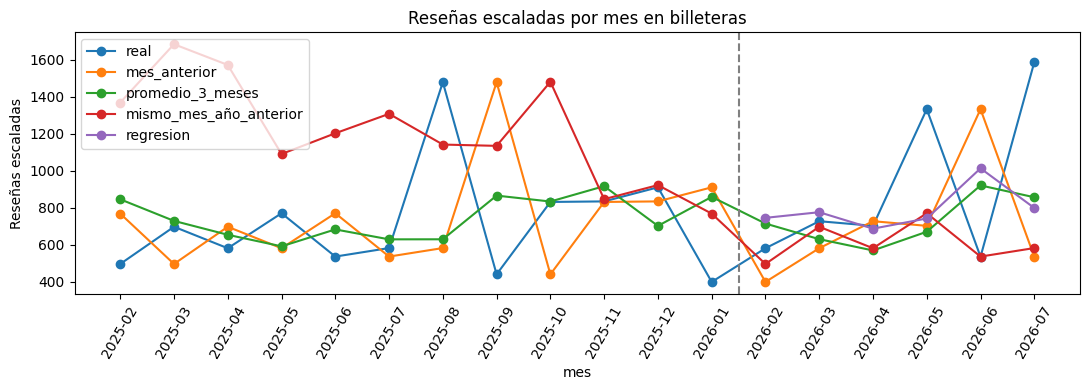

,real,mes_anterior,promedio_3_meses,mismo_mes_año_anterior,regresion
mes,,,,,
2026-02,581,399.0,714.0,496.0,745.0
2026-03,727,581.0,630.0,697.0,776.0
2026-04,702,727.0,569.0,581.0,687.0
2026-05,1332,702.0,670.0,770.0,742.0
2026-06,535,1332.0,920.0,536.0,1013.0
2026-07,1586,535.0,856.0,582.0,799.0


In [579]:
### 20.2 (continuación) MAE e intervalo de 95 % de cada método
filas = []
for metodo in METODOS:
    if metodo == "regresion":
        errores_ajuste = residuos_regresion
    else:
        errores_ajuste = (ajuste["real"] - ajuste[metodo]).dropna()
    abajo = np.percentile(errores_ajuste, 2.5)
    arriba = np.percentile(errores_ajuste, 97.5)
    limite_abajo = prueba_serie[metodo] + abajo
    limite_arriba = prueba_serie[metodo] + arriba
    dentro = ((prueba_serie["real"] >= limite_abajo) & (prueba_serie["real"] <= limite_arriba)).mean()
    error = (prueba_serie["real"] - prueba_serie[metodo]).abs()
    filas.append({
        "Método": metodo,
        "MAE (últimos 6 meses)": error.mean(),
        "Error % medio": (error / prueba_serie["real"]).mean(),
        "IC 2,5% (error)": abajo,
        "IC 97,5% (error)": arriba,
        "% de meses dentro del IC": dentro,
    })
comparacion_pronostico = pd.DataFrame(filas).set_index("Método").sort_values("MAE (últimos 6 meses)")
display(comparacion_pronostico.round(2))

# gráfico de los últimos 18 meses (la línea punteada separa ajuste y prueba)
grafico = serie[["real"] + METODOS].iloc[-18:]
grafico.index = grafico.index.astype(str)
grafico.plot(figsize=(11, 4), marker="o", title="Reseñas escaladas por mes en billeteras")
plt.axvline(len(grafico) - N_MESES_PRUEBA - 0.5, color="gray", ls="--")
plt.xticks(range(len(grafico)), grafico.index, rotation=60)
plt.ylabel("Reseñas escaladas")
plt.tight_layout()
plt.show()
prueba_serie[["real"] + METODOS].round(0)

In [580]:
### 20.3 Plan de capacidad
# No está en las plantillas: lo pide el brief (cuántas revisa un analista al día,
# cuántas atiende cada equipo y qué pasa si llegan más)
CAPACIDAD_ANALISTA = 40  # Supuesto: reseñas por analista al día
PERCENTIL_PICO = 95  # Se planea para el día del percentil 95
ESCENARIOS_USUARIOS = [2, 5, 10, 20]  # Millones de usuarios de Brío

# tamaño de los picos: día del percentil 95 frente al promedio (Nequi y DaviPlata, 2026)
recientes["dia"] = pd.to_datetime(recientes["fecha"]).dt.date
NOMBRE_PICO = "Percentil " + str(PERCENTIL_PICO)
filas = []
for app in USUARIOS_COMPETIDORES:
    por_dia = recientes[recientes["app"] == app].groupby("dia")["escalar"].sum()
    filas.append({
        "App": app,
        "Promedio por día": por_dia.mean(),
        NOMBRE_PICO: np.percentile(por_dia, PERCENTIL_PICO),
        "Máximo": por_dia.max(),
    })
picos = pd.DataFrame(filas).set_index("App")
picos["Factor de pico"] = picos[NOMBRE_PICO] / picos["Promedio por día"]
FACTOR_PICO = picos["Factor de pico"].mean()
display(picos.round(2))

# analistas necesarios según el tamaño de Brío
filas = []
for usuarios in ESCENARIOS_USUARIOS:
    normal = usuarios * NEG_POR_MILLON * PCT_ESCALAR
    pico = normal * FACTOR_PICO
    filas.append({
        "Usuarios (millones)": usuarios,
        "Escaladas día normal": normal,
        "Escaladas día pico": pico,
        "Graves día normal": normal * PRECISION_REGLA / SENSIBILIDAD_REGLA,
        "Analistas (día normal)": int(np.ceil(normal / CAPACIDAD_ANALISTA)),
        "Analistas (día pico)": int(np.ceil(pico / CAPACIDAD_ANALISTA)),
        "% de un analista ocupado": normal / CAPACIDAD_ANALISTA,
    })
display(pd.DataFrame(filas).set_index("Usuarios (millones)").round(2))

# por equipo en el escenario elegido (USUARIOS_BRIO)
pico_equipo = por_equipo["Escaladas por día (Brío)"] * FACTOR_PICO
por_equipo["Escaladas día pico (Brío)"] = pico_equipo
por_equipo.round(2)

,Promedio por día,Percentil 95,Máximo,Factor de pico
App,,,,
nequi,10.68,19.00,44,1.78
daviplata,15.10,52.45,90,3.47


,Escaladas día normal,Escaladas día pico,Graves día normal,Analistas (día normal),Analistas (día pico),% de un analista ocupado
Usuarios (millones),,,,,,
2,1.19,3.12,0.54,1,1,0.03
5,2.97,7.79,1.36,1,1,0.07
10,5.94,15.59,2.72,1,1,0.15
20,11.87,31.18,5.44,1,1,0.30


,% de las escaladas,Escaladas por día (Brío),Graves por día (Brío),Escaladas día pico (Brío)
equipo_sugerido,,,,
acceso_identidad,0.39,1.16,0.49,3.06
pagos_transferencias,0.37,1.10,0.46,2.88
tecnologia_app,0.08,0.24,0.10,0.64
otro,0.08,0.24,0.10,0.63
seguridad_fraude,0.06,0.16,0.07,0.43
servicio_cliente,0.01,0.03,0.01,0.08
cobros_tarifas,0.01,0.03,0.01,0.08


In [581]:
### 20.4 Si llegan más de las que se pueden atender: prioridad de la cola
EQUIPOS_PLATA = ["seguridad_fraude", "pagos_transferencias", "cobros_tarifas"] # Hay plata en riesgo: van primero
PROB_ALTA = 0.5 # Probabilidad de grave (regresión logística) desde la que la prioridad es alta

def prioridad(tabla, prob):
    # alta: escalada y con plata en riesgo o probabilidad alta; media: escalada; baja: no escalada
    escalar = REGLAS[REGLA_REFERENCIA](tabla) == 1
    plata = enrutar(tabla, ORDEN_TEMAS).isin(EQUIPOS_PLATA)
    return np.where(escalar & (plata | (prob >= PROB_ALTA)), "alta", np.where(escalar, "media", "baja"))

recientes["prob_grave"] = probabilidad_log(recientes)
recientes["prioridad"] = prioridad(recientes, recientes["prob_grave"])
cola = recientes[recientes["escalar"] == 1]
resumen_cola = cola.groupby("prioridad").agg(reseñas=("id", "count"), prob_media=("prob_grave", "mean"))
resumen_cola["% de la cola"] = resumen_cola["reseñas"] / len(cola)
resumen_cola["Por día (Brío, normal)"] = resumen_cola["% de la cola"] * escaladas_dia
resumen_cola["Por día (Brío, pico)"] = resumen_cola["Por día (Brío, normal)"] * FACTOR_PICO
resumen_cola.round(2)

,reseñas,prob_media,% de la cola,"Por día (Brío, normal)","Por día (Brío, pico)"
prioridad,,,,,
alta,2760,0.49,0.47,1.40,3.67
media,3102,0.23,0.53,1.57,4.12


In [582]:
### 20.5 Valor del sistema frente a la regla simple (billeteras, prueba)
COSTO_UNIDAD_COP = 4_500_000 / (21 * CAPACIDAD_ANALISTA) # Supuesto: analista con costo total de $4,5 millones al mes, 21 días, 40 reseñas por día

valor = tabla_prueba(billeteras)[["Costo por 1.000", "IC 2,5%", "IC 97,5%"]].copy()
valor["Unidades por día (Brío)"] = valor["Costo por 1.000"] / 1000 * negativas_dia
valor["Pesos por mes (Brío)"] = valor["Unidades por día (Brío)"] * COSTO_UNIDAD_COP * 30
valor["Diferencia vs regla (por 1.000)"] = valor["Costo por 1.000"] - valor.loc[REGLA_REFERENCIA, "Costo por 1.000"]
valor["Diferencia vs regla (pesos por mes)"] = valor["Pesos por mes (Brío)"] - valor.loc[REGLA_REFERENCIA, "Pesos por mes (Brío)"]
print("Costo de una unidad: $", round(COSTO_UNIDAD_COP), "| negativas por día de Brío:", round(negativas_dia, 2))
valor.round(1)

Costo de una unidad: $ 5357 | negativas por día de Brío: 5.37


,Costo por 1.000,"IC 2,5%","IC 97,5%",Unidades por día (Brío),Pesos por mes (Brío),Diferencia vs regla (por 1.000),Diferencia vs regla (pesos por mes)
Decisión,,,,,,,
No escalar ninguna,1392.4,949.4,1898.7,7.5,1201559.1,911.4,786474.8
Escalar todas,721.5,620.3,810.1,3.9,622626.1,240.5,207541.8
Regla temas + dinero,481.0,316.5,696.2,2.6,415084.4,0.0,0.0
Regresión logística,531.6,329.1,772.2,2.9,458777.5,50.6,43693.1
Árbol de decisión,759.5,519.0,1050.9,4.1,655396.2,278.5,240311.8
Bosque aleatorio,645.6,367.1,987.3,3.5,557086.9,164.6,142002.5
Boosting,658.2,392.4,1000.0,3.5,568009.9,177.2,152925.6


Precisión de la regla: 0.36 | sensibilidad: 0.889


,tipo_app,Reseñas,Negativas,Escaladas,Graves estimadas,% negativas,Índice de desafecto
app,,,,,,,
daviplata,billetera,7730.0,5454,3201,1297.70,0.71,167.88
colpatria,banco tradicional,1338.0,926,494,200.27,0.69,149.68
avvillas,banco tradicional,545.0,351,165,66.89,0.64,122.74
agrario,banco tradicional,303.0,207,91,36.89,0.68,121.76
bogota,banco tradicional,2463.0,1690,725,293.92,0.69,119.33
movii,billetera,801.0,373,212,85.95,0.47,107.30
davivienda,banco tradicional,6498.0,3884,1696,687.57,0.60,105.81
bancolombia,banco tradicional,4829.0,2197,1092,442.70,0.45,91.68
bbva,banco tradicional,1442.0,477,278,112.70,0.33,78.16


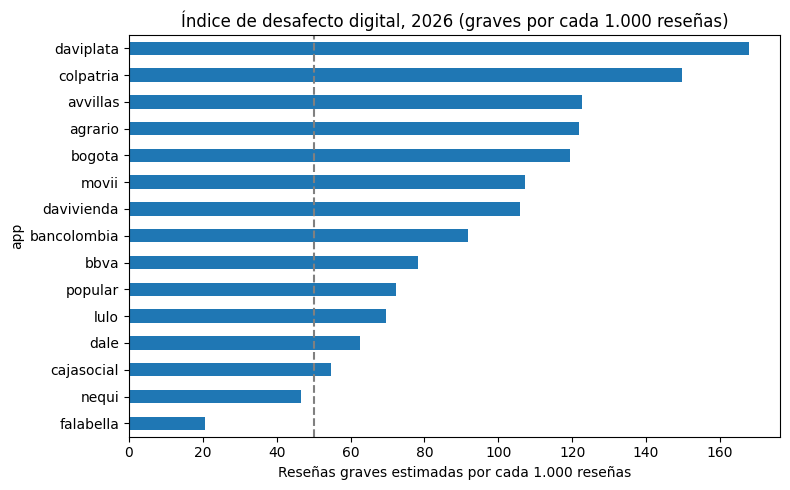

,Reseñas,Negativas,Graves estimadas,Índice de desafecto
tipo_app,,,,
banco digital,951.0,248,66.1,69.5
banco tradicional,22434.0,11010,2084.2,92.9
billetera,29385.0,10605,2376.5,80.9


In [583]:
### 20.6 Índice de desafecto digital (lo pide el brief para el resumen ejecutivo y el memo)
# Definición: reseñas GRAVES estimadas por cada 1.000 reseñas de la app (de todas las estrellas), en 2026.
# Graves estimadas = escaladas por la regla × precisión / sensibilidad de la regla en prueba
# (la precisión descuenta las leves que la regla escala de más; la sensibilidad suma las graves que deja pasar)
DESDE_INDICE = "2026-01-01" # Mismo periodo reciente del despliegue

y_r = decisiones[REGLA_REFERENCIA]
PRECISION_TODAS = ((y_r == 1) & (y_pru == 1)).sum() / (y_r == 1).sum()      # prueba completa
SENSIBILIDAD_TODAS = ((y_r == 1) & (y_pru == 1)).sum() / (y_pru == 1).sum()  # prueba completa
print("Precisión de la regla:", round(PRECISION_TODAS, 3), "| sensibilidad:", round(SENSIBILIDAD_TODAS, 3))

# aplicar la regla a todas las negativas de 2026
neg_indice = preparar(neg[pd.to_datetime(neg["fecha"]) >= DESDE_INDICE])
neg_indice["escalar"] = REGLAS[REGLA_REFERENCIA](neg_indice)

indice = pd.DataFrame({
    "tipo_app": neg_indice.groupby("app")["tipo_app"].first(),
    "Reseñas": panel[panel["mes"] >= DESDE_INDICE].groupby("app")["n_resenas"].sum(),   # todas las estrellas (panel)
    "Negativas": neg_indice.groupby("app").size(),
    "Escaladas": neg_indice.groupby("app")["escalar"].sum(),
})
indice["Graves estimadas"] = indice["Escaladas"] * PRECISION_TODAS / SENSIBILIDAD_TODAS
indice["% negativas"] = indice["Negativas"] / indice["Reseñas"]
indice["Índice de desafecto"] = indice["Graves estimadas"] / indice["Reseñas"] * 1000
display(indice.sort_values("Índice de desafecto", ascending=False).round(2))

# gráfico por app
indice["Índice de desafecto"].sort_values().plot.barh(figsize=(8, 5), title="Índice de desafecto digital, 2026 (graves por cada 1.000 reseñas)")
plt.axvline(50, color="gray", ls="--")   # meta propuesta para Brío: nivel de Nequi
plt.xlabel("Reseñas graves estimadas por cada 1.000 reseñas")
plt.tight_layout()
plt.show()

# por tipo de app
por_tipo = indice.groupby("tipo_app")[["Reseñas", "Negativas", "Graves estimadas"]].sum()
por_tipo["Índice de desafecto"] = por_tipo["Graves estimadas"] / por_tipo["Reseñas"] * 1000
por_tipo.round(1)

In [584]:
## 21. Modelo final como pipeline para la app (README de la plantilla, PASO 2)
# La plantilla exige un Pipeline: la app le pasa el texto y las variables tal como vienen,
# y el TF-IDF y la estandarización ocurren adentro. Es la misma logística de la sección 12.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

COLUMNAS_ENTRADA = ["texto_n"] + numericas  # Texto normalizado + las 12 variables numéricas

preparacion = ColumnTransformer([
    ("texto", TfidfVectorizer(ngram_range=(1, 2), min_df=2), "texto_n"),  # mismo TF-IDF de la sección 10
    ("num", StandardScaler(), numericas),  # mismo z-score de la sección 10
])
mi_pipeline = Pipeline([
    ("preparacion", preparacion),
    ("modelo", LogisticRegression(C=C_REGULARIZACION, max_iter=1000)),
])

X_train = X_ent[COLUMNAS_ENTRADA].copy()
X_train["texto_n"] = X_train["texto_n"].fillna("")
X_test = X_pru[COLUMNAS_ENTRADA].copy()
X_test["texto_n"] = X_test["texto_n"].fillna("")
mi_pipeline.fit(X_train, y_ent)

# Verificar que es el mismo modelo de la sección 12
prob_pipeline = mi_pipeline.predict_proba(X_test)[:, 1]
decision_pipeline = (prob_pipeline >= UMBRAL).astype(int)
decision_seccion_12 = decisiones["Regresión logística"].values
print("Costo en prueba (pipeline):", costo(y_pru.values, decision_pipeline))
print("Costo en prueba (sección 12):", costo(y_pru.values, decision_seccion_12))
print("AUC (pipeline):", round(roc_auc_score(y_pru, prob_pipeline), 3))
print("Decisiones distintas:", int((decision_pipeline != decision_seccion_12).sum()))

Costo en prueba (pipeline): 535.0
Costo en prueba (sección 12): 535.0
AUC (pipeline): 0.792
Decisiones distintas: 0


In [585]:
## 22. Exportar el modelo a la app (plantilla del profesor: Exportar_modelo_desde_Colab.ipynb)
import os
import sys
import importlib
CARPETA_APP = RUTA + "plantilla_app"  # La carpeta plantilla_app subida a Drive
print("¿Está exportar.py?", os.path.exists(CARPETA_APP + "/exportar.py"))
if CARPETA_APP not in sys.path:
    sys.path.append(CARPETA_APP)
importlib.invalidate_caches()  # que Python vuelva a mirar la carpeta (antes estaba vacía)
from exportar import exportar

N_BANDEJA = 20  # Reseñas de ejemplo para la bandeja (brief: unas 20 recientes de billeteras)
# ids de reseñas con datos personales (nombres, celulares): se revisan abajo y se agregan aquí
EXCLUIR_BANDEJA = ["5dc817b4-8061-43fd-b2a4-352c0f3fb23f"]  # trae un nombre propio

# 1. Métricas en prueba (costo por 1.000) y su intervalo
rng = np.random.default_rng(SEMILLA)
muestras = [rng.integers(0, len(y_pru), len(y_pru)) for _ in range(N_BOOT)]
ahorro = []
for m in muestras:
    y_m = y_pru.iloc[m].values
    costo_regla_m = costo(y_m, decisiones[REGLA_REFERENCIA].iloc[m].values)
    costo_modelo_m = costo(y_m, decisiones["Regresión logística"].iloc[m].values)
    ahorro.append(costo_regla_m - costo_modelo_m)

TEXTO_REGLA = ("Escalar si la reseña habla de fraude, plata que no llega, "
               "acceso o bloqueo, o cobros, o si menciona dinero")
TEXTO_UNIDAD = "por cada 1.000 reseñas negativas (5 por grave perdida, 1 por leve escalada)"
metricas = {
    "costo_modelo": float(costo(y_pru, decisiones["Regresión logística"])),
    "costo_regla": float(costo(y_pru, decisiones[REGLA_REFERENCIA])),
    "regla_simple": TEXTO_REGLA,
    "unidad_costo": TEXTO_UNIDAD,
    "intervalo_diferencia": [float(np.percentile(ahorro, 2.5)), float(np.percentile(ahorro, 97.5))],
    "Costo regla en billeteras": round(float(valor.loc[REGLA_REFERENCIA, "Costo por 1.000"]), 1),
    "Costo modelo en billeteras": round(float(valor.loc["Regresión logística", "Costo por 1.000"]), 1),
    "Usuarios supuestos de Brío (millones)": USUARIOS_BRIO,
    "Negativas por día (Brío)": round(float(negativas_dia), 1),
    "Escaladas por día (Brío)": round(float(escaladas_dia), 1),
    "Graves por día (Brío)": round(float(graves_dia), 1),
    "Analistas necesarios": 1,
}
print(metricas)

# 2. Bandeja: 20 reseñas recientes de billeteras (12 que la regla escala y 8 que no)
candidatas = recientes[(recientes["n_palabras"] >= 8) & (recientes["n_palabras"] <= 60)]
candidatas = candidatas[~candidatas["id"].isin(EXCLUIR_BANDEJA)]
escaladas = candidatas[candidatas["escalar"] == 1].sample(12, random_state=SEMILLA)
no_escaladas = candidatas[candidatas["escalar"] == 0].sample(N_BANDEJA - 12, random_state=SEMILLA)
bandeja = pd.concat([escaladas, no_escaladas]).reset_index(drop=True)
bandeja["texto_n"] = bandeja["texto_n"].fillna("")
bandeja["caso"] = ["Reseña " + str(i + 1) for i in range(len(bandeja))]
bandeja["regla"] = np.where(bandeja["escalar"] == 1, "Escalar", "No escalar")
bandeja["equipo_sugerido"] = enrutar(bandeja, ORDEN_TEMAS)
prob_bandeja = mi_pipeline.predict_proba(bandeja[COLUMNAS_ENTRADA])[:, 1]
bandeja["prioridad"] = prioridad(bandeja, prob_bandeja)
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fechas = pd.to_datetime(bandeja["fecha"])
bandeja["fecha"] = [f"{f.day} {MESES[f.month - 1]} {f.year}" for f in fechas]

# Revisar a mano: ¿alguna trae nombre, celular, cédula o número de cuenta? (Ley 1581 de 2012)
for i, fila in bandeja.iterrows():
    print(fila["id"], "|", fila["text"][:200])

# 3. Nombres de negocio de las columnas
etiquetas = {
    "texto_n": "Texto de la reseña",
    "score": "Estrellas",
    "n_palabras": "Número de palabras",
    "tema_fraude": "Habla de fraude",
    "tema_fallas_app": "Habla de fallas de la app",
    "tema_plata_no_llega": "Habla de plata que no llega",
    "tema_acceso_bloqueo": "Habla de acceso o bloqueo",
    "tema_cobros": "Habla de cobros",
    "tema_atencion": "Habla de atención",
    "menciona_dinero": "Menciona dinero",
    "menciona_espera": "Dice cuánto lleva esperando",
    "pct_mayusculas": "Mayúsculas por palabra",
    "n_exclamaciones": "Signos de exclamación",
    "caso": "Caso",
    "app": "App",
    "text": "Reseña",
    "regla": "Decisión de la regla",
    "equipo_sugerido": "Equipo sugerido",
    "prioridad": "Prioridad",
}

# 4. Exportar
exportar(
    modelo=mi_pipeline,
    X_entrenamiento=X_train,
    umbrales=[UMBRAL],
    decisiones=["No escalar", "Escalar"],
    metricas=metricas,
    evento="reseña grave",
    tabla_resultados=bandeja,
    columna_id="caso",
    columnas_a_mostrar=["app", "fecha", "text", "regla", "equipo_sugerido", "prioridad"],
    columnas_texto=["texto_n"],
    etiquetas=etiquetas,
    enmascarar_texto=True,  # cambia números largos y correos por [número] y [correo]
)

# 5. Tablas agregadas para las pestañas de competencia (solo agregados por app: lo permite el brief)
COLUMNAS_QUEJAS = ["quejas"] + ["quejas_" + t.replace("tema_", "") for t in TEMAS]
quejas_app = panel.groupby("app")[COLUMNAS_QUEJAS].sum()
competencia = X.copy()  # % de negativas por tema (sección 19)
for tema in TEMAS:
    nombre = tema.replace("tema_", "")
    competencia["quejas_pct_" + nombre] = quejas_app["quejas_" + nombre] / quejas_app["quejas"]
competencia["tipo_app"] = segmentos["tipo_app"]
competencia["grupo"] = segmentos["Grupo"]
competencia["indice_desafecto"] = indice["Índice de desafecto"]
competencia.round(4).to_csv(CARPETA_APP + "/model/competencia.csv")
valor.round(1).to_csv(CARPETA_APP + "/model/valor.csv")
por_equipo.round(3).to_csv(CARPETA_APP + "/model/por_equipo.csv")
print("Archivos de la app:", sorted(os.listdir(CARPETA_APP + "/model")))

¿Está exportar.py? True
{'costo_modelo': 535.0, 'costo_regla': 480.0, 'regla_simple': 'Escalar si la reseña habla de fraude, plata que no llega, acceso o bloqueo, o cobros, o si menciona dinero', 'unidad_costo': 'por cada 1.000 reseñas negativas (5 por grave perdida, 1 por leve escalada)', 'intervalo_diferencia': [-145.0, 30.0], 'Costo regla en billeteras': 481.0, 'Costo modelo en billeteras': 531.6, 'Usuarios supuestos de Brío (millones)': 5.0, 'Negativas por día (Brío)': 5.4, 'Escaladas por día (Brío)': 3.0, 'Graves por día (Brío)': 1.4, 'Analistas necesarios': 1}
efc0fa8c-dc58-4219-9a6f-3e23a5b3b276 | No entiendo como Google Play descontó dinero de mi tarjeta DALE si nunca les dí la información de ella y nunca me suscribí a google play, me parece que dale no es confiable.
4650d863-e77a-48fd-89b2-da56c6198cdd | Me gusta pero no me parece que cobren por la tarjeta física si es la primera vez que se va a solicitar
e4cf7afa-db9a-4627-aa45-9c24eea18f1e | Muchachos por lo menos hagan un e

In [586]:
%%writefile "/content/drive/MyDrive/Proyecto BRIO/plantilla_app/app.py"
"""ZONA LIBRE: la interfaz de la aplicación (adaptada al caso Brío).
Ya funciona con cualquier modelo exportado con exportar.py. Desde aquí la adaptan a su caso:
cambien textos, orden, gráficos y colores, con ayuda de IA si quieren (PASO 5 de la guía).
Lo único que debe quedar es el pie de página al final.

Para verla en su computador:   streamlit run app.py"""
from pathlib import Path

import pandas as pd
import streamlit as st
import brio

from core import (cargar_config, cargar_metadata, cargar_modelo, cargar_resultados, etiqueta, evaluar,
                  hay_modelo, texto_razon, validar)

config = cargar_config()
st.set_page_config(page_title=config["titulo"], layout="wide")
CARPETA_MODELO = Path(__file__).resolve().parent / "model"


# ---------------------------------------------------------------------------------------------
# Encabezado: título, cliente y descripción vienen de mi_app.py
# ---------------------------------------------------------------------------------------------
col_logo, col_titulo = st.columns([1, 5])
with col_logo:
    try:
        st.image(config["logo"], width=150)
    except Exception:
        pass
with col_titulo:
    st.title(config["titulo"])
    st.caption(f"{config['cliente']} · {config['descripcion']}")


# ---------------------------------------------------------------------------------------------
# Mientras no exporten su modelo, la app muestra la guía en lugar de fallar
# ---------------------------------------------------------------------------------------------
if not hay_modelo():
    st.info("Todavía no hay modelo en la carpeta model/. Sigan la guía del README.")
    st.divider()
    st.caption(config["pie"])
    st.stop()


@st.cache_resource
def recursos():
    return cargar_metadata(), cargar_modelo(), cargar_resultados()


@st.cache_data
def tabla_extra(nombre):
    """Tablas agregadas que exportó la celda 22 (competencia, valor, por equipo)."""
    ruta = CARPETA_MODELO / nombre
    if not ruta.exists():
        return None
    return pd.read_csv(ruta, index_col=0)


meta, modelo, resultados = recursos()
evento = meta["evento"]
unidad = config["unidad"]
m = meta["metricas"]
NOMBRE_PRIORIDAD = {"alta": "🔴 Alta", "media": "🟠 Media", "baja": "🟢 Baja"}

# Brief: "Si al final la regla simple le gana al modelo, la recomendación lo debe decir claramente"
st.info(
    f"**Recomendación:** la **regla simple** decide qué reseñas escalar, porque en la prueba ningún modelo le "
    f"ganó (regla {m['costo_regla']:.0f} frente a modelo {m['costo_modelo']:.0f}, costo {m['unidad_costo']}). "
    "El modelo se usa para **ordenar la cola** por prioridad."
)


def mostrar_resultado(probabilidad, decision, razones):
    """Probabilidad del modelo y sus razones."""
    st.metric(f"Probabilidad de {evento} (modelo)", f"{probabilidad:.0%}")
    if not razones:
        st.caption("Con estos valores ninguna variable mueve la probabilidad frente a un caso típico.")
    else:
        st.markdown("**Lo que más movió la probabilidad del modelo**")
        for r in razones:
            if isinstance(r, dict):
                st.markdown(f"- {texto_razon(r, meta)}")
            else:
                st.markdown(f"- {r}")
        st.caption("Las razones muestran de qué depende la predicción del modelo, no qué pasaría si algo cambiara.")


def formulario_nuevo():
    """Se pega el texto de la reseña y la app calcula sola las 13 variables del modelo (brio.py)."""
    with st.form("nuevo"):
        texto = st.text_area("Texto de la reseña", height=120,
                             placeholder="Ej.: Me robaron la plata y no me llega la transferencia, llevo 3 días")
        estrellas = st.radio("Estrellas", [1, 2, 3], horizontal=True)
        enviado = st.form_submit_button("Evaluar")
    if not enviado:
        return
    if len(texto.split()) < 3:
        st.warning("La reseña es muy corta para decidir si es grave.")
    fila = brio.preparar_resena(texto, estrellas)
    datos, errores, avisos = validar(fila, meta)
    for e in errores:
        st.error(e)
    if errores:
        return
    r = evaluar(modelo, meta, datos)[0]
    escalar = brio.regla(fila) == 1
    equipo = brio.enrutar(fila)
    prioridad = brio.prioridad(escalar, equipo, r["probabilidad"])

    c1, c2, c3 = st.columns(3)
    c1.metric("Decisión (regla simple)", "Escalar" if escalar else "No escalar")
    c2.metric("Equipo sugerido", brio.NOMBRE_EQUIPO[equipo] if escalar else "—")
    c3.metric("Prioridad", NOMBRE_PRIORIDAD[prioridad])
    temas = brio.temas_detectados(fila)
    st.markdown("**Temas detectados en el texto:** " + (", ".join(temas) if temas else "ninguno"))
    mostrar_resultado(r["probabilidad"], r["decision"], r["razones"])
    st.caption("Decide la regla simple; el modelo ordena la cola. Una persona de triaje confirma el equipo.")


def buscar_en_lista():
    col_id = meta.get("columna_id")
    if resultados is None or not col_id or col_id not in resultados.columns:
        st.info("No exportaron una tabla de resultados con columna_id para buscar.")
        return
    elegido = st.selectbox(f"Busquen {unidad} de la bandeja", resultados[col_id].astype(str))
    fila = resultados[resultados[col_id].astype(str) == elegido].iloc[0]
    st.markdown(f"> {fila['text']}")
    c1, c2, c3 = st.columns(3)
    c1.metric("Decisión (regla simple)", fila["regla"])
    equipo = brio.NOMBRE_EQUIPO.get(fila["equipo_sugerido"], fila["equipo_sugerido"])
    c2.metric("Equipo sugerido", equipo if fila["regla"] == "Escalar" else "—")
    c3.metric("Prioridad", NOMBRE_PRIORIDAD.get(fila["prioridad"], fila["prioridad"]))
    razones = [r for r in str(fila.get("razones", "")).split(" · ") if r and r != "nan"]
    mostrar_resultado(float(fila["probabilidad"]), fila["decision"], razones)


def vista_lista():
    """Bandeja de un día cualquiera: 20 reseñas recientes de billeteras ordenadas por prioridad."""
    if resultados is None:
        st.info("Exporten una tabla de resultados (tabla_resultados en exportar) para ver aquí la lista.")
        return
    st.write("20 reseñas recientes de billeteras (2026), revisadas para quitar datos personales, "
             "en el orden en que las atendería el equipo: primero la prioridad alta.")
    t = resultados.copy()
    t["_orden"] = t["prioridad"].map({"alta": 0, "media": 1, "baja": 2})
    t = t.sort_values(["_orden", "probabilidad"], ascending=[True, False])
    t["Prioridad"] = t["prioridad"].map(NOMBRE_PRIORIDAD)
    t["Equipo sugerido"] = [brio.NOMBRE_EQUIPO.get(e, e) if d == "Escalar" else "—"
                            for e, d in zip(t["equipo_sugerido"], t["regla"])]
    t["Probabilidad (modelo)"] = (t["probabilidad"] * 100).round(0).astype(int).astype(str) + " %"
    vista = t[["caso", "Prioridad", "regla", "Equipo sugerido", "Probabilidad (modelo)", "app", "fecha", "text"]]
    vista = vista.rename(columns={"caso": "Caso", "regla": "Decisión (regla)", "app": "App",
                                  "fecha": "Fecha", "text": "Reseña"})
    opciones = list(NOMBRE_PRIORIDAD.values())
    elegidas = st.multiselect("Prioridad", opciones, default=opciones)
    vista = vista[vista["Prioridad"].isin(elegidas)]
    c1, c2, c3 = st.columns(3)
    c1.metric("Reseñas en la bandeja", len(t))
    c2.metric("Para escalar", int((t["regla"] == "Escalar").sum()))
    c3.metric("Prioridad alta", int((t["prioridad"] == "alta").sum()))
    st.dataframe(vista, width="stretch", hide_index=True)


def vista_competencia():
    """Brief: temas de las reseñas negativas y de las quejas formales por app y por tipo de app."""
    c = tabla_extra("competencia.csv")
    if c is None:
        st.info("No hay tabla de competencia exportada (celda 22 del cuaderno).")
        return
    temas = list(brio.NOMBRE_TEMA)
    resenas = c[["pct_" + t for t in temas]].copy()
    resenas.columns = [brio.NOMBRE_TEMA[t] for t in temas]
    quejas = c[["quejas_pct_" + t for t in temas]].copy()
    quejas.columns = resenas.columns

    st.markdown("**Índice de desafecto digital (2026):** reseñas graves estimadas por cada 1.000 reseñas de "
                "la app. Meta propuesta para Brío: menos de 50, el nivel de Nequi.")
    st.bar_chart(c["indice_desafecto"].sort_values(ascending=False), horizontal=True)

    por = st.radio("Ver por", ["Tipo de app", "App"], horizontal=True)
    if por == "Tipo de app":
        st.markdown("**% de las reseñas negativas que toca cada tema**")
        st.bar_chart(resenas.groupby(c["tipo_app"]).mean(), stack=False)
        st.markdown("**% de las quejas formales (Superfinanciera) por tema**")
        st.bar_chart(quejas.groupby(c["tipo_app"]).mean(), stack=False)
    else:
        st.markdown("**% de las reseñas negativas que toca cada tema**")
        st.dataframe((resenas * 100).round(1), width="stretch")
        st.markdown("**% de las quejas formales (Superfinanciera) por tema**")
        st.dataframe((quejas * 100).round(1), width="stretch")
        st.caption("Movii no tiene quejas formales reportadas en el panel.")

    grupos = "; ".join(f"{g}: {', '.join(sorted(c.index[c['grupo'] == g]))}" for g in sorted(c["grupo"].unique()))
    st.markdown(f"**Grupos de K-Means:** {grupos}")
    st.caption("Las billeteras y neobancos del grupo C2 se quejan más de fraude, atención y acceso; los bancos "
               "del C1, de fallas de la app. Es asociación, no causa. Ninguna de estas apps es cliente de Brío.")


def vista_valor():
    c1, c2, c3 = st.columns(3)
    c1.metric("Costo con el modelo", f"{m['costo_modelo']:,.0f}".replace(",", "."))
    c2.metric("Costo con la regla simple", f"{m['costo_regla']:,.0f}".replace(",", "."))
    ahorro = m["costo_regla"] - m["costo_modelo"]
    c3.metric("Ahorro del modelo frente a la regla", f"{ahorro:,.0f}".replace(",", "."))
    st.caption(f"Costos {m['unidad_costo']}, en 200 reseñas de prueba (desde julio de 2025).")
    st.markdown(f"**Regla simple:** {m['regla_simple']}.")
    if "intervalo_diferencia" in m:
        a, b = m["intervalo_diferencia"]
        st.markdown(f"Intervalo de 95 % del ahorro: de {a:.0f} a {b:.0f}. Como incluye el cero, no se puede "
                    "afirmar que el modelo le gane a la regla: **por eso decide la regla**.")

    st.markdown("**Lo que debe esperar Brío**")
    d1, d2, d3, d4 = st.columns(4)
    d1.metric("Negativas por día", m.get("Negativas por día (Brío)", "—"))
    d2.metric("Escaladas por día", m.get("Escaladas por día (Brío)", "—"))
    d3.metric("Graves por día", m.get("Graves por día (Brío)", "—"))
    d4.metric("Analistas necesarios", m.get("Analistas necesarios", "—"))
    st.caption(f"Supuesto: {m.get('Usuarios supuestos de Brío (millones)', 5)} millones de usuarios, con la tasa "
               "de reseñas negativas por usuario de Nequi y DaviPlata en 2026. Un analista revisa 40 reseñas al "
               "día; en un día pico llegan unas 2,6 veces más.")
    e = tabla_extra("por_equipo.csv")
    if e is not None and "Escaladas por día (Brío)" in e.columns:
        st.markdown("**Reseñas escaladas por equipo (por día)**")
        st.bar_chart(e.rename(index=brio.NOMBRE_EQUIPO)["Escaladas por día (Brío)"], horizontal=True)
    v = tabla_extra("valor.csv")
    if v is not None:
        st.markdown("**Solo billeteras (como Brío)**")
        st.dataframe(v, width="stretch")


def vista_regla():
    st.markdown(f"""
1. **¿Se escala?** Decide la **regla simple**: {m['regla_simple'].lower()}.
2. **¿A qué equipo?** Al del tema más grave que toque la reseña: fraude → plata → cobros → acceso → fallas →
   atención. Sin tema, va a «otro». Una persona de triaje confirma el equipo.
3. **¿Con qué prioridad?** **Alta** si hay plata en riesgo (fraude, pagos o cobros) o el modelo da 50 % o más;
   **media**, el resto de las escaladas. Si llegan más de las que se pueden atender, la alta va el mismo día.
4. **El modelo** (regresión logística sobre el texto y 12 variables) da la probabilidad de grave. Se usa para
   ordenar la cola, no para decidir. Su regla propia sería:
""")
    filas = []
    limites = [0.0] + meta["umbrales"] + [1.0]
    for i, d in enumerate(meta["decisiones"]):
        filas.append({f"Probabilidad de {evento}": f"{limites[i]:.0%} a {limites[i + 1]:.0%}", "El modelo diría": d})
    st.table(pd.DataFrame(filas))
    st.caption(f"Modelo entrenado con {meta['n_entrenamiento']} reseñas etiquetadas por el equipo; "
               f"exportado el {meta['fecha_exportacion']}.")


# ---------------------------------------------------------------------------------------------
# Cuerpo de la app. PASO 5: adapten pestañas, textos y gráficos a lo que necesita su cliente.
# ---------------------------------------------------------------------------------------------
if config["interfaz"] == "html":
    from core.web import construir_html
    st.iframe(construir_html(), height=820)
    with st.expander(f"Evaluar {unidad} nuevo"):
        formulario_nuevo()
else:
    nombres = [f"Evaluar {unidad}", "Bandeja del día", "Competencia", "Cuánto vale el modelo", "Cómo decide"]
    pestanas = st.tabs(nombres)
    with pestanas[0]:
        modo = st.radio("¿Qué quieren hacer?", ["Pegar una reseña", "Buscar en la bandeja"], horizontal=True)
        if modo == "Pegar una reseña":
            formulario_nuevo()
        else:
            buscar_en_lista()
    with pestanas[1]:
        vista_lista()
    with pestanas[2]:
        vista_competencia()
    with pestanas[3]:
        vista_valor()
    with pestanas[4]:
        vista_regla()


# Pie de página: debe quedar (atribuciones y advertencias de su caso, en mi_app.py)
st.divider()
st.caption(config["pie"])

Overwriting /content/drive/MyDrive/Proyecto BRIO/plantilla_app/app.py


In [587]:
# Ajustes visuales de app.py: % en Competencia y paréntesis del recuadro
ruta_app = RUTA + "plantilla_app/app.py"
contenido = open(ruta_app, encoding="utf-8").read()

cambios = [
    ('resenas = c[["pct_" + t for t in temas]].copy()',
     'resenas = c[["pct_" + t for t in temas]].copy() * 100'),
    ('quejas = c[["quejas_pct_" + t for t in temas]].copy()',
     'quejas = c[["quejas_pct_" + t for t in temas]].copy() * 100'),
    ('st.dataframe((resenas * 100).round(1)', 'st.dataframe(resenas.round(1)'),
    ('st.dataframe((quejas * 100).round(1)', 'st.dataframe(quejas.round(1)'),
    ('f"ganó (regla ', 'f"ganó: regla '),
    (", costo {m['unidad_costo']}). \"", ", costo {m['unidad_costo']}. \""),
]
for viejo, nuevo in cambios:
    if nuevo in contenido:
        print("YA ESTABA", viejo[:45])
    else:
        print("OK  " if viejo in contenido else "NO ESTÁ  ", viejo[:45])
        contenido = contenido.replace(viejo, nuevo)

open(ruta_app, "w", encoding="utf-8").write(contenido)

OK   resenas = c[["pct_" + t for t in temas]].copy
OK   quejas = c[["quejas_pct_" + t for t in temas]
OK   st.dataframe((resenas * 100).round(1)
OK   st.dataframe((quejas * 100).round(1)
OK   f"ganó (regla 
OK   , costo {m['unidad_costo']}). "


13606

In [588]:
## 23. Revisar y desplegar la app (plantilla del profesor: Desplegar_desde_Colab.ipynb)
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

import sys
import importlib
carpeta_app = RUTA + "plantilla_app"
if carpeta_app not in sys.path:
    sys.path.append(carpeta_app)
importlib.invalidate_caches()

from desplegar import desplegar
desplegar(carpeta_app)

Mounted at /content/drive
Entorno detectado: Google Colab (Python 3.13.18). Carpeta de la app: /content/drive/MyDrive/Proyecto BRIO/plantilla_app

1. Instalar las librerías de requirements.txt
Listo.

2. Revisar la app con check.py
Revisando la app...

[OK]    archivos de la plantilla
[OK]    zona fija sin cambios
[OK]    mi_app.py completo
[OK]    modelo exportado con sus métricas: 13 variables, umbrales [0.12], decisiones ['No escalar', 'Escalar']
[OK]    versiones en requirements.txt
[OK]    el modelo carga, predice y explica: 11% → No escalar, 10% → No escalar, 66% → Escalar
[OK]    resultados.csv: 20 filas. Revisen que cumpla las condiciones de uso de los datos de su caso
[OK]    la opción HTML se arma: 0.0 MB
[OK]    el repositorio no lleva los datos del curso
[OK]    pie de página y marca de datos del HTML
[OK]    app.py corre de principio a fin

LISTO PARA DESPLEGAR


3. Probar la app
Abran el enlace que aparece abajo para probar la app (funciona mientras esta sesión de Colab e

<IPython.core.display.Javascript object>


4. Archivos para GitHub
Quedó para_subir_a_github.zip con 24 archivos (sin datos del curso).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Cómo subirlos a GitHub desde el navegador:
  a. Descompriman el .zip en su computador.
  b. En github.com abran su repositorio privado (o créenlo en https://github.com/new).
  c. Elijan "Add file" → "Upload files" y arrastren TODO el contenido de la carpeta descomprimida
     (las carpetas también), no la carpeta misma.
  d. Abajo, escriban un mensaje corto y presionen "Commit changes".
  Si ya habían subido una versión, suban los archivos otra vez: GitHub reemplaza los que cambiaron.

5. Publicar en Streamlit Community Cloud
  a. Entren a https://share.streamlit.io con su cuenta de GitHub.
     La primera vez, autoricen el acceso a sus repositorios privados.
  b. Elijan "Create app" y la opción de desplegar desde un repositorio de GitHub
     (la app queda pública; el repositorio sigue privado).
  c. Repository: su repositorio. Branch: main. Main file path: app.py
  d. En "Advanced settings" elijan Python 3.13 (la misma versión con que exportaron el modelo).
  e. Presionen "Deploy" y

<Popen: returncode: None args: ['/usr/bin/python3', '-m', 'streamlit', 'run'...>